# VoltRelay Energy — Data Analytics & Business Insights

**Hackathon Project | Data Analysis**

**Objective:** Analyze EV battery-swapping operations to identify service-quality issues, operational inefficiencies, customer experience problems and revenue opportunities.

**Tools Used:** Microsoft Excel, Python, Pandas, Matplotlib, Google Colab.

**Datasets:** 8 datasets covering swap events, stations, riders, batteries, support tickets, fleet partners and city-level context.

**Analysis Period:** January 2024 – June 2025.

In [4]:
import zipfile
import glob
import os

# Find the uploaded ZIP file
zip_files = glob.glob("/content/*.zip")

print("Uploaded ZIP files:", zip_files)

Uploaded ZIP files: ['/content/VoltRelay_Cleaned_Datasets_and_Report (4).zip']


In [11]:
import os

zip_path = "/content/VoltRelay_Cleaned_Datasets_and_Report (4).zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("File size:", os.path.getsize(zip_path), "bytes")

    with open(zip_path, "rb") as f:
        print("File header:", f.read(20))

File exists: True
File size: 198424179 bytes
File header: b'PK\x03\x04\x14\x00\x00\x00\x08\x00\xf9Eo]\xefP\xe2\xe4\xb7\x01'


In [8]:
import zipfile

zip_path = "/content/VoltRelay_Cleaned_Datasets_and_Report (4).zip"

try:
    with zipfile.ZipFile(zip_path, "r") as z:
        print("ZIP integrity:", z.testzip())
except Exception as e:
    print("ZIP error:", e)

ZIP error: File is not a zip file


In [12]:
import zipfile

zip_path = "/content/VoltRelay_Cleaned_Datasets_and_Report (4).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    result = z.testzip()

if result is None:
    print("SUCCESS: ZIP file is valid!")
else:
    print("Corrupted file:", result)

SUCCESS: ZIP file is valid!


In [13]:
import zipfile
import os

zip_path = "/content/VoltRelay_Cleaned_Datasets_and_Report (4).zip"
extract_path = "/content/VoltRelay_Cleaned"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("SUCCESS! Datasets extracted.")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(file)

SUCCESS! Datasets extracted.
stations_cleaned.csv
swap_event_quality_flags.csv
swap_quality_flag_summary.csv
station_hourly_status_cleaned.csv
batteries_cleaned.csv
swap_events_cleaned.csv
support_tickets_cleaned.csv
fleet_partners_cleaned.csv
missing_values_summary.csv
riders_cleaned.csv
DATA_QUALITY_REPORT.md
city_daily_context_cleaned.csv
cleaning_log.csv
timestamp_review_candidates.csv
offline_batch_duplicate_candidates.csv


In [14]:
import pandas as pd
import os
import glob

folder = "/content/VoltRelay_Cleaned"

files = glob.glob(folder + "/**/*.csv", recursive=True)

print("TOTAL CSV FILES:", len(files))

for file in files:
    name = os.path.basename(file)
    size_mb = os.path.getsize(file) / (1024 * 1024)

    df = pd.read_csv(file, nrows=3)

    print("\n" + "=" * 60)
    print("FILE:", name)
    print("SIZE:", round(size_mb, 2), "MB")
    print("COLUMNS:", list(df.columns))
    print("SAMPLE:")
    display(df.head(2))

TOTAL CSV FILES: 14

FILE: stations_cleaned.csv
SIZE: 0.02 MB
COLUMNS: ['station_id', 'city', 'zone', 'latitude', 'longitude', 'location_type', 'host_type', 'commissioned_date', 'decommissioned_date', 'expansion_wave', 'charger_generation', 'slots_2w', 'slots_3w', 'inventory_target_2w', 'inventory_target_3w', 'monthly_rent_inr', 'monthly_maintenance_inr', 'grid_tariff_inr_kwh', 'connectivity_tier', 'firmware_version', 'firmware_updated_date', 'competitor_within_1_5km_since']
SAMPLE:


,station_id,city,zone,latitude,longitude,location_type,host_type,commissioned_date,decommissioned_date,expansion_wave,...,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh,connectivity_tier,firmware_version,firmware_updated_date,competitor_within_1_5km_since
0,STN-BLR-001,Bengaluru,BLR-Electronic City,12.926943,77.604655,transit_hub,mall_parking,2023-12-09,NaN,Launch,...,6,32,7,23247,5436,9.29,good,v3.2.1,2025-04-14,NaN
1,STN-BLR-002,Bengaluru,BLR-Central,13.149199,77.530565,commercial_hub,kirana,2023-06-20,NaN,Launch,...,0,38,0,23201,5249,8.41,poor,v3.2.1,2025-04-14,NaN



FILE: swap_event_quality_flags.csv
SIZE: 1.84 MB
COLUMNS: ['event_id', 'event_ts', 'station_firmware', 'field', 'raw_value', 'issue']
SAMPLE:


,event_id,event_ts,station_firmware,field,raw_value,issue
0,SW-000000001,2024-01-01 11:10:56,v3.2.1,soh_in_pct,100.6,SOH above 100% — verify sensor/calibration
1,SW-000000018,2024-01-01 08:40:07,v3.2.0,soh_in_pct,100.1,SOH above 100% — verify sensor/calibration



FILE: swap_quality_flag_summary.csv
SIZE: 0.0 MB
COLUMNS: ['field', 'issue', 'flagged_rows']
SAMPLE:


,field,issue,flagged_rows
0,km_since_last_swap,Negative distance — invalid value; verify tele...,7814
1,soc_out_pct,SOC above 100% — invalid percentage range,3698


... (18 outputs left out)


FILE: timestamp_review_candidates.csv
SIZE: 27.54 MB
COLUMNS: ['event_id', 'station_id', 'event_ts', 'station_firmware', 'review_note']
SAMPLE:


,event_id,station_id,event_ts,station_firmware,review_note
0,SW-002671234,STN-JAI-135,2025-03-10 12:53:23,v3.2.0,Potential firmware v3.2.0 timestamp offset (~5...
1,SW-002671235,STN-JAI-135,2025-03-10 08:04:09,v3.2.0,Potential firmware v3.2.0 timestamp offset (~5...



FILE: offline_batch_duplicate_candidates.csv
SIZE: 0.0 MB
COLUMNS: ['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type', 'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id', 'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct', 'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr', 'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh', 'station_firmware', 'sync_mode', 'review_note']
SAMPLE:


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode,review_note
0,SW-003121515,RD-1012648,STN-DEL-039,2025-04-23 19:20:56,swap_completed,1,297,BAT-2W-104320,BAT-2W-101265,2.8,...,51.5,PARTNER,65.0,18.2,46.8,partner_invoice,1.684,v3.2.1,offline_batch,"Same rider, station, timestamp and event_type ..."
1,SW-003121516,RD-1012648,STN-DEL-039,2025-04-23 19:20:56,swap_completed,1,107,BAT-2W-105423,BAT-2W-101204,1.1,...,40.4,PARTNER,65.0,18.2,46.8,partner_invoice,1.672,v3.2.1,offline_batch,"Same rider, station, timestamp and event_type ..."


In [15]:
import pandas as pd
import os

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

monthly_results = []

for chunk in pd.read_csv(file_path, chunksize=200000):

    chunk["event_ts"] = pd.to_datetime(
        chunk["event_ts"], errors="coerce"
    )

    chunk["month"] = chunk["event_ts"].dt.to_period("M").astype(str)

    chunk["amount_charged_inr"] = pd.to_numeric(
        chunk["amount_charged_inr"], errors="coerce"
    )

    chunk["queue_wait_sec"] = pd.to_numeric(
        chunk["queue_wait_sec"], errors="coerce"
    )

    summary = chunk.groupby(
        ["month", "event_type"], dropna=False
    ).agg(
        total_events=("event_id", "count"),
        revenue_inr=("amount_charged_inr", "sum"),
        avg_queue_wait_sec=("queue_wait_sec", "mean")
    ).reset_index()

    monthly_results.append(summary)

monthly = pd.concat(monthly_results)

monthly = monthly.groupby(
    ["month", "event_type"]
).agg(
    total_events=("total_events", "sum"),
    revenue_inr=("revenue_inr", "sum"),
    avg_queue_wait_sec=("avg_queue_wait_sec", "mean")
).reset_index()

print("MONTHLY NETWORK PERFORMANCE")
display(monthly.head(30))

print("\nEVENT TYPES FOUND")
print(monthly.groupby("event_type")["total_events"].sum())

monthly.to_csv(
    "/content/VoltRelay_monthly_performance.csv",
    index=False
)

print("\nMonthly analysis saved successfully!")

MONTHLY NETWORK PERFORMANCE


,month,event_type,total_events,revenue_inr,avg_queue_wait_sec
0,2024-01,abandoned_queue,1405,0.0,702.567972
1,2024-01,cancelled_by_rider,445,0.0,44.979775
2,2024-01,failed_no_charged_battery,2690,0.0,29.100000
3,2024-01,failed_system_error,318,0.0,42.496855
4,2024-01,swap_completed,105490,6318995.2,243.027178
5,2024-02,abandoned_queue,1451,0.0,702.209465
6,2024-02,cancelled_by_rider,471,0.0,45.603498
7,2024-02,failed_no_charged_battery,2681,0.0,29.871210
8,2024-02,failed_system_error,346,0.0,45.762500
9,2024-02,swap_completed,106582,6387614.8,243.999208



EVENT TYPES FOUND
event_type
abandoned_queue                68533
cancelled_by_rider             16712
failed_no_charged_battery     134389
failed_system_error            11570
swap_completed               3645809
Name: total_events, dtype: int64

Monthly analysis saved successfully!


## 2. Data Cleaning and Quality Checks

Data cleaning was performed to improve consistency and reliability before analysis.

The following actions were taken:

- Removed leading and trailing whitespace from text fields.
- Standardized city names and aliases.
- Preserved missing values instead of replacing them with zeros or fabricated values.
- Checked duplicate records and key columns.
- Identified unusual SOC, SOH, queue wait and distance values.
- Flagged potential offline batch duplicate events for review.
- Identified firmware-related timestamp review candidates.
- Preserved original records and avoided unsupported corrections.

**Data quality considerations:**

- 139,490 timestamp records were flagged for review.
- Potential duplicate candidates were retained for investigation.
- Missing CSAT values were not imputed.
- Unusual measurements were flagged rather than automatically deleted.

The cleaned datasets were used for subsequent exploratory data analysis.

In [16]:
import pandas as pd

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

monthly_data = []

for chunk in pd.read_csv(file_path, chunksize=200000):

    chunk["event_ts"] = pd.to_datetime(
        chunk["event_ts"], errors="coerce"
    )

    chunk["month"] = chunk["event_ts"].dt.to_period("M").astype(str)

    summary = chunk.groupby(["month", "event_type"]).agg(
        total_events=("event_id", "count")
    ).reset_index()

    monthly_data.append(summary)

# Combine all chunks
monthly_counts = pd.concat(monthly_data)

monthly_counts = monthly_counts.groupby(
    ["month", "event_type"]
)["total_events"].sum().reset_index()

# Convert event types into columns
pivot = monthly_counts.pivot(
    index="month",
    columns="event_type",
    values="total_events"
).fillna(0)

# Calculate monthly rates
pivot["total_attempts"] = pivot.sum(axis=1)

pivot["completion_rate_pct"] = (
    pivot["swap_completed"] / pivot["total_attempts"] * 100
)

pivot["failure_rate_pct"] = (
    (pivot["failed_no_charged_battery"] +
     pivot["failed_system_error"]) /
    pivot["total_attempts"] * 100
)

pivot["abandonment_rate_pct"] = (
    pivot["abandoned_queue"] / pivot["total_attempts"] * 100
)

display(pivot.round(2))

pivot.to_csv(
    "/content/VoltRelay_monthly_failure_analysis.csv"
)

print("Monthly failure analysis saved!")

event_type,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,total_attempts,completion_rate_pct,failure_rate_pct,abandonment_rate_pct
month,,,,,,,,,
2024-01,1405,445,2690,318,105490,110348,95.60,2.73,1.27
2024-02,1451,471,2681,346,106582,111531,95.56,2.71,1.30
2024-03,1575,549,2938,394,118444,123900,95.60,2.69,1.27
2024-04,2683,524,5382,393,122836,131818,93.19,4.38,2.04
2024-05,5520,670,11313,447,128328,146278,87.73,8.04,3.77
2024-06,4596,638,9452,459,133743,148888,89.83,6.66,3.09
2024-07,2025,653,3734,452,151824,158688,95.67,2.64,1.28
2024-08,2185,755,3955,469,164931,172295,95.73,2.57,1.27
2024-09,2442,830,4690,621,187302,195885,95.62,2.71,1.25


Monthly failure analysis saved!


In [19]:
print(monthly.columns.tolist())

['month', 'event_type', 'total_events', 'revenue_inr', 'avg_queue_wait_sec']


In [20]:
# Convert event types into separate columns
monthly_pivot = monthly.pivot(
    index="month",
    columns="event_type",
    values="total_events"
).fillna(0)

# Calculate total attempts
monthly_pivot["total_attempts"] = monthly_pivot.sum(axis=1)

# Calculate completion rate
monthly_pivot["completion_rate_pct"] = (
    monthly_pivot["swap_completed"] /
    monthly_pivot["total_attempts"] * 100
)

# Calculate failure rate
monthly_pivot["failure_rate_pct"] = (
    (monthly_pivot["failed_no_charged_battery"] +
     monthly_pivot["failed_system_error"]) /
    monthly_pivot["total_attempts"] * 100
)

display(monthly_pivot.head())

event_type,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,total_attempts,completion_rate_pct,failure_rate_pct
month,,,,,,,,
2024-01,1405,445,2690,318,105490,110348,95.597564,2.725922
2024-02,1451,471,2681,346,106582,111531,95.562669,2.714044
2024-03,1575,549,2938,394,118444,123900,95.596449,2.689266
2024-04,2683,524,5382,393,122836,131818,93.186060,4.381041
2024-05,5520,670,11313,447,128328,146278,87.728845,8.039486


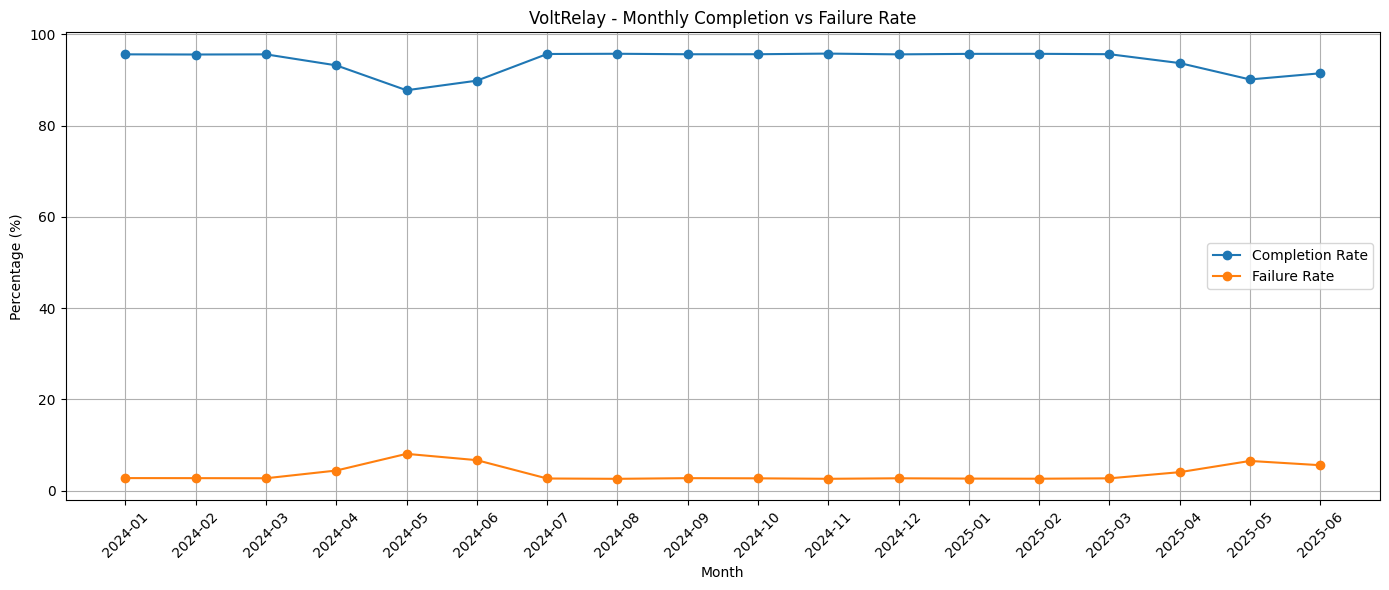

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_pivot.index,
    monthly_pivot["completion_rate_pct"],
    marker="o",
    label="Completion Rate"
)

plt.plot(
    monthly_pivot.index,
    monthly_pivot["failure_rate_pct"],
    marker="o",
    label="Failure Rate"
)

plt.title("VoltRelay - Monthly Completion vs Failure Rate")
plt.xlabel("Month")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd

# Load cleaned station dataset
stations = pd.read_csv(
    "/content/VoltRelay_Cleaned/stations_cleaned.csv"
)

# Inspect station information
print("Total stations:", len(stations))
print("\nAvailable columns:")
print(stations.columns.tolist())

display(stations.head())

Total stations: 152

Available columns:
['station_id', 'city', 'zone', 'latitude', 'longitude', 'location_type', 'host_type', 'commissioned_date', 'decommissioned_date', 'expansion_wave', 'charger_generation', 'slots_2w', 'slots_3w', 'inventory_target_2w', 'inventory_target_3w', 'monthly_rent_inr', 'monthly_maintenance_inr', 'grid_tariff_inr_kwh', 'connectivity_tier', 'firmware_version', 'firmware_updated_date', 'competitor_within_1_5km_since']


,station_id,city,zone,latitude,longitude,location_type,host_type,commissioned_date,decommissioned_date,expansion_wave,...,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh,connectivity_tier,firmware_version,firmware_updated_date,competitor_within_1_5km_since
0,STN-BLR-001,Bengaluru,BLR-Electronic City,12.926943,77.604655,transit_hub,mall_parking,2023-12-09,NaN,Launch,...,6,32,7,23247,5436,9.29,good,v3.2.1,2025-04-14,NaN
1,STN-BLR-002,Bengaluru,BLR-Central,13.149199,77.530565,commercial_hub,kirana,2023-06-20,NaN,Launch,...,0,38,0,23201,5249,8.41,poor,v3.2.1,2025-04-14,NaN
2,STN-BLR-003,Bengaluru,BLR-Electronic City,12.917986,77.607560,commercial_hub,fuel_retailer,2023-09-26,NaN,Launch,...,0,43,0,10281,4516,8.66,good,v3.2.1,2025-04-14,NaN
3,STN-BLR-004,Bengaluru,BLR-Whitefield,13.030901,77.489397,market,mall_parking,2023-08-25,NaN,Launch,...,0,33,0,12322,5802,9.19,good,v3.2.1,2025-04-14,NaN
4,STN-BLR-005,Bengaluru,BLR-North,12.815864,77.628712,residential,mall_parking,2023-11-07,NaN,Launch,...,0,15,0,24194,7134,8.68,fair,v3.2.1,2025-04-14,NaN


In [23]:
# Check number of stations in each city
city_station_count = (
    stations.groupby("city")["station_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Number of stations in each city:")
display(city_station_count)

print("\nUnique cities:", stations["city"].nunique())
print("Missing city values:", stations["city"].isna().sum())

Number of stations in each city:


,station_id
city,
Bengaluru,34
Delhi NCR,30
Hyderabad,26
Mumbai,22
Pune,22
Jaipur,18



Unique cities: 6
Missing city values: 0


In [24]:
import pandas as pd

# Create station-to-city mapping
station_city = stations[["station_id", "city"]].copy()

# Initialize an empty dictionary for city-level counts
city_results = {}

# Read large transaction file in chunks
file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

for chunk in pd.read_csv(file_path, chunksize=200000):

    # Attach city to each transaction
    chunk = chunk.merge(
        station_city,
        on="station_id",
        how="left"
    )

    # Count event types for each city
    city_counts = (
        chunk.groupby(["city", "event_type"])
        .size()
        .unstack(fill_value=0)
    )

    # Add results across chunks
    for city in city_counts.index:
        if city not in city_results:
            city_results[city] = city_counts.loc[city].copy()
        else:
            city_results[city] = (
                city_results[city].add(
                    city_counts.loc[city],
                    fill_value=0
                )
            )

# Combine results
city_performance = pd.DataFrame(city_results).T.fillna(0)

print("City-wise transaction counts:")
display(city_performance)

City-wise transaction counts:


event_type,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed
Bengaluru,10919,3621,20602,2488,787697
Delhi NCR,17030,3301,33892,2305,712385
Hyderabad,14158,3033,28274,2153,664312
Jaipur,11518,2073,23303,1374,449366
Mumbai,6827,2313,12838,1603,506718
Pune,8081,2371,15480,1647,525331


In [25]:
# Calculate total swap attempts per city
city_performance["total_attempts"] = city_performance.sum(axis=1)

# Calculate completion rate
city_performance["completion_rate_pct"] = (
    city_performance["swap_completed"] /
    city_performance["total_attempts"] * 100
)

# Calculate technical failure rate
city_performance["failure_rate_pct"] = (
    (
        city_performance["failed_no_charged_battery"] +
        city_performance["failed_system_error"]
    ) / city_performance["total_attempts"] * 100
)

# Calculate abandonment rate
city_performance["abandonment_rate_pct"] = (
    city_performance["abandoned_queue"] /
    city_performance["total_attempts"] * 100
)

# Add station counts
city_performance["station_count"] = (
    city_performance.index.map(city_station_count)
)

# Display important metrics
city_summary = city_performance[
    [
        "station_count",
        "total_attempts",
        "swap_completed",
        "completion_rate_pct",
        "failure_rate_pct",
        "abandonment_rate_pct"
    ]
].sort_values("failure_rate_pct", ascending=False)

display(city_summary.round(2))

event_type,station_count,total_attempts,swap_completed,completion_rate_pct,failure_rate_pct,abandonment_rate_pct
Jaipur,18,487634,449366,92.15,5.06,2.36
Delhi NCR,30,768913,712385,92.65,4.71,2.21
Hyderabad,26,711930,664312,93.31,4.27,1.99
Pune,22,552910,525331,95.01,3.10,1.46
Bengaluru,34,825327,787697,95.44,2.80,1.32
Mumbai,22,530299,506718,95.55,2.72,1.29


## 1. Data Understanding and Loading

In this section, we load the eight datasets provided for the VoltRelay Energy hackathon.

The datasets cover:
- Swap transactions
- Station information
- Hourly station status
- Rider information
- Battery information
- Customer support tickets
- Fleet partner information
- City-level daily context

The objective is to understand the structure, size, columns and quality of the available data before performing analysis.

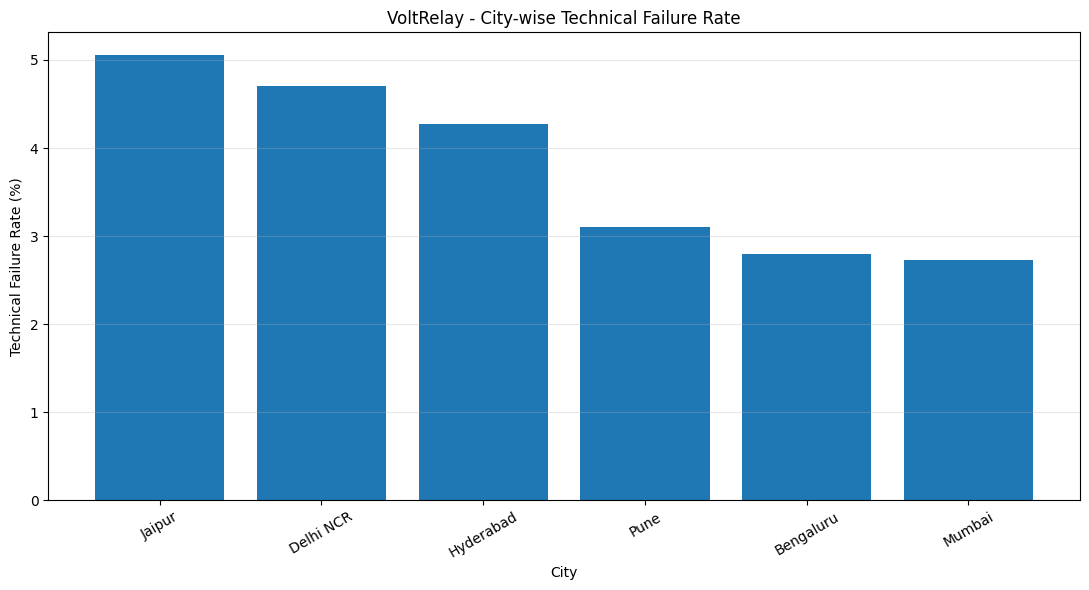

In [26]:
import matplotlib.pyplot as plt

city_chart = city_summary.sort_values(
    "failure_rate_pct",
    ascending=False
)

plt.figure(figsize=(11, 6))

plt.bar(
    city_chart.index,
    city_chart["failure_rate_pct"]
)

plt.title("VoltRelay - City-wise Technical Failure Rate")
plt.xlabel("City")
plt.ylabel("Technical Failure Rate (%)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Initialize station-level results
station_results = {}

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

for chunk in pd.read_csv(file_path, chunksize=200000):

    station_counts = (
        chunk.groupby(["station_id", "event_type"])
        .size()
        .unstack(fill_value=0)
    )

    for station in station_counts.index:
        if station not in station_results:
            station_results[station] = station_counts.loc[station].copy()
        else:
            station_results[station] = (
                station_results[station].add(
                    station_counts.loc[station],
                    fill_value=0
                )
            )

# Combine station results
station_performance = pd.DataFrame(
    station_results
).T.fillna(0)

# Add city information
station_performance = station_performance.merge(
    stations[["station_id", "city", "zone"]],
    left_index=True,
    right_on="station_id",
    how="left"
)

print("Total stations analyzed:", len(station_performance))
display(station_performance.head())

Total stations analyzed: 152


,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,station_id,city,zone
0,376,96,693,82,25006,STN-BLR-001,Bengaluru,BLR-Electronic City
1,369,124,781,74,29568,STN-BLR-002,Bengaluru,BLR-Central
2,487,152,961,120,38521,STN-BLR-003,Bengaluru,BLR-Electronic City
3,700,231,1335,158,49670,STN-BLR-004,Bengaluru,BLR-Whitefield
4,345,144,710,80,25101,STN-BLR-005,Bengaluru,BLR-North


In [28]:
# Calculate total attempts per station
event_columns = [
    "abandoned_queue",
    "cancelled_by_rider",
    "failed_no_charged_battery",
    "failed_system_error",
    "swap_completed"
]

station_performance["total_attempts"] = (
    station_performance[event_columns].sum(axis=1)
)

# Completion rate
station_performance["completion_rate_pct"] = (
    station_performance["swap_completed"] /
    station_performance["total_attempts"] * 100
)

# Technical failure rate
station_performance["failure_rate_pct"] = (
    (
        station_performance["failed_no_charged_battery"] +
        station_performance["failed_system_error"]
    ) / station_performance["total_attempts"] * 100
)

# Abandonment rate
station_performance["abandonment_rate_pct"] = (
    station_performance["abandoned_queue"] /
    station_performance["total_attempts"] * 100
)

# Display 10 stations with highest failure rates
worst_stations = station_performance.sort_values(
    "failure_rate_pct",
    ascending=False
)

display(
    worst_stations[
        [
            "station_id",
            "city",
            "zone",
            "total_attempts",
            "completion_rate_pct",
            "failure_rate_pct",
            "abandonment_rate_pct"
        ]
    ].head(10).round(2)
)

,station_id,city,zone,total_attempts,completion_rate_pct,failure_rate_pct,abandonment_rate_pct
36,STN-DEL-037,Delhi NCR,DEL-Noida,30838,90.92,5.91,2.77
47,STN-DEL-048,Delhi NCR,DEL-West,34646,91.02,5.75,2.78
137,STN-JAI-138,Jaipur,JAI-Malviya Nagar,48945,91.33,5.69,2.53
44,STN-DEL-045,Delhi NCR,DEL-Noida,32237,91.28,5.68,2.61
135,STN-JAI-136,Jaipur,JAI-Malviya Nagar,29340,91.29,5.67,2.57
140,STN-JAI-141,Jaipur,JAI-Malviya Nagar,45594,91.27,5.66,2.66
136,STN-JAI-137,Jaipur,JAI-Malviya Nagar,44371,91.25,5.63,2.69
49,STN-DEL-050,Delhi NCR,DEL-East,47060,91.39,5.62,2.55
139,STN-JAI-140,Jaipur,JAI-Malviya Nagar,44115,91.54,5.59,2.46
42,STN-DEL-043,Delhi NCR,DEL-East,49597,91.39,5.55,2.63


In [29]:
# Select the 10 worst-performing stations
top10_ids = worst_stations.head(10)["station_id"]

# Select useful station attributes
station_details = stations[
    [
        "station_id",
        "city",
        "zone",
        "location_type",
        "host_type",
        "charger_generation",
        "connectivity_tier",
        "firmware_version",
        "slots_2w",
        "slots_3w",
        "monthly_maintenance_inr"
    ]
]

# Merge with performance data
top10_analysis = worst_stations[
    worst_stations["station_id"].isin(top10_ids)
].merge(
    station_details,
    on="station_id",
    how="left",
    suffixes=("_performance", "_details")
)

display(top10_analysis)

,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,station_id,city_performance,zone_performance,total_attempts,completion_rate_pct,...,city_details,zone_details,location_type,host_type,charger_generation,connectivity_tier,firmware_version,slots_2w,slots_3w,monthly_maintenance_inr
0,854,122,1728,95,28039,STN-DEL-037,Delhi NCR,DEL-Noida,30838,90.923536,...,Delhi NCR,DEL-Noida,commercial_hub,owned_lot,Gen1,good,v3.2.1,16,0,6869
1,962,158,1894,97,31535,STN-DEL-048,Delhi NCR,DEL-West,34646,91.020608,...,Delhi NCR,DEL-West,market,owned_lot,Gen1,good,v3.2.0,16,0,6190
2,1239,218,2635,150,44703,STN-JAI-138,Jaipur,JAI-Malviya Nagar,48945,91.333129,...,Jaipur,JAI-Malviya Nagar,market,kirana,Gen1,poor,v3.2.1,12,0,4667
3,841,140,1716,114,29426,STN-DEL-045,Delhi NCR,DEL-Noida,32237,91.280206,...,Delhi NCR,DEL-Noida,commercial_hub,owned_lot,Gen1,good,v3.2.1,16,0,6346
4,753,139,1570,93,26785,STN-JAI-136,Jaipur,JAI-Malviya Nagar,29340,91.291752,...,Jaipur,JAI-Malviya Nagar,transit_hub,mall_parking,Gen1,good,v3.2.0,8,6,7177
5,1215,185,2474,107,41613,STN-JAI-141,Jaipur,JAI-Malviya Nagar,45594,91.268588,...,Jaipur,JAI-Malviya Nagar,commercial_hub,mall_parking,Gen1,good,v3.2.1,16,0,5066
6,1192,191,2380,118,40490,STN-JAI-137,Jaipur,JAI-Malviya Nagar,44371,91.253296,...,Jaipur,JAI-Malviya Nagar,commercial_hub,owned_lot,Gen1,fair,v3.2.1,8,0,5391
7,1202,204,2513,134,43007,STN-DEL-050,Delhi NCR,DEL-East,47060,91.387590,...,Delhi NCR,DEL-East,commercial_hub,fuel_retailer,Gen1,poor,v3.2.1,12,0,5342
8,1084,181,2347,121,40382,STN-JAI-140,Jaipur,JAI-Malviya Nagar,44115,91.538026,...,Jaipur,JAI-Malviya Nagar,commercial_hub,mall_parking,Gen1,fair,v3.2.0,16,0,5885
9,1306,211,2611,143,45326,STN-DEL-043,Delhi NCR,DEL-East,49597,91.388592,...,Delhi NCR,DEL-East,commercial_hub,mall_parking,Gen1,poor,v3.2.1,12,0,6507


In [30]:
# Identify the 10 worst-performing stations
top10_ids = set(worst_stations.head(10)["station_id"])

# Divide all stations into two groups
station_comparison = stations.copy()

station_comparison["performance_group"] = (
    station_comparison["station_id"].apply(
        lambda x: "Top 10 high-failure stations"
        if x in top10_ids
        else "Other 142 stations"
    )
)

# Compare station characteristics
for column in [
    "charger_generation",
    "connectivity_tier",
    "firmware_version"
]:
    print("\nComparison:", column)

    comparison = pd.crosstab(
        station_comparison["performance_group"],
        station_comparison[column],
        normalize="index"
    ) * 100

    display(comparison.round(2))


Comparison: charger_generation


charger_generation,Gen1,Gen2,Gen3
performance_group,,,
Other 142 stations,28.87,45.07,26.06
Top 10 high-failure stations,100.00,0.00,0.00



Comparison: connectivity_tier


connectivity_tier,fair,good,poor
performance_group,,,
Other 142 stations,19.01,66.9,14.08
Top 10 high-failure stations,20.00,50.0,30.00



Comparison: firmware_version


firmware_version,v3.2.0,v3.2.1
performance_group,,
Other 142 stations,40.85,59.15
Top 10 high-failure stations,30.00,70.00


In [31]:
# Merge station characteristics with performance metrics
generation_analysis = station_performance.merge(
    stations[
        ["station_id", "charger_generation", "connectivity_tier"]
    ],
    on="station_id",
    how="left"
)

# Compare average station failure rates by generation
generation_summary = (
    generation_analysis
    .groupby("charger_generation")
    .agg(
        station_count=("station_id", "nunique"),
        avg_failure_rate=("failure_rate_pct", "mean"),
        avg_completion_rate=("completion_rate_pct", "mean"),
        total_attempts=("total_attempts", "sum")
    )
    .sort_values("avg_failure_rate", ascending=False)
)

display(generation_summary.round(2))

,station_count,avg_failure_rate,avg_completion_rate,total_attempts
charger_generation,,,,
Gen1,51,4.60,92.83,1822034
Gen3,37,3.02,95.12,372241
Gen2,64,3.01,95.13,1682738


In [32]:
# Combine station transactions with charger generation
generation_data = station_performance.merge(
    stations[["station_id", "charger_generation"]],
    on="station_id",
    how="left"
)

# Aggregate actual transaction counts
generation_volume = (
    generation_data.groupby("charger_generation")
    .agg(
        total_attempts=("total_attempts", "sum"),
        completed=("swap_completed", "sum"),
        battery_failures=("failed_no_charged_battery", "sum"),
        system_failures=("failed_system_error", "sum")
    )
)

# Calculate transaction-weighted rates
generation_volume["failure_rate_pct"] = (
    (generation_volume["battery_failures"] +
     generation_volume["system_failures"]) /
    generation_volume["total_attempts"] * 100
)

generation_volume["completion_rate_pct"] = (
    generation_volume["completed"] /
    generation_volume["total_attempts"] * 100
)

display(generation_volume.round(2))

,total_attempts,completed,battery_failures,system_failures,failure_rate_pct,completion_rate_pct
charger_generation,,,,,,
Gen1,1822034,1690298,79144,5355,4.64,92.77
Gen2,1682738,1601293,45168,5100,2.99,95.16
Gen3,372241,354218,10077,1115,3.01,95.16


In [33]:
connectivity_data = station_performance.merge(
    stations[["station_id", "connectivity_tier"]],
    on="station_id",
    how="left"
)

connectivity_summary = (
    connectivity_data.groupby("connectivity_tier")
    .agg(
        station_count=("station_id", "nunique"),
        total_attempts=("total_attempts", "sum"),
        completed=("swap_completed", "sum"),
        battery_failures=("failed_no_charged_battery", "sum"),
        system_failures=("failed_system_error", "sum")
    )
)

connectivity_summary["failure_rate_pct"] = (
    (connectivity_summary["battery_failures"] +
     connectivity_summary["system_failures"]) /
    connectivity_summary["total_attempts"] * 100
)

connectivity_summary["completion_rate_pct"] = (
    connectivity_summary["completed"] /
    connectivity_summary["total_attempts"] * 100
)

display(connectivity_summary.round(2))

,station_count,total_attempts,completed,battery_failures,system_failures,failure_rate_pct,completion_rate_pct
connectivity_tier,,,,,,,
fair,29,669686,627498,24790,1987,4.00,93.70
good,100,2565470,2416645,86118,7694,3.66,94.20
poor,23,641857,601666,23481,1889,3.95,93.74


In [34]:
import pandas as pd

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

hourly_results = []

for chunk in pd.read_csv(file_path, chunksize=200000):

    chunk["event_ts"] = pd.to_datetime(
        chunk["event_ts"], errors="coerce"
    )

    chunk["queue_wait_sec"] = pd.to_numeric(
        chunk["queue_wait_sec"], errors="coerce"
    )

    chunk = chunk.dropna(subset=["event_ts"])

    chunk["hour"] = chunk["event_ts"].dt.hour

    chunk["completed"] = (
        chunk["event_type"] == "swap_completed"
    ).astype(int)

    chunk["abandoned"] = (
        chunk["event_type"] == "abandoned_queue"
    ).astype(int)

    chunk["battery_failures"] = (
        chunk["event_type"] == "failed_no_charged_battery"
    ).astype(int)

    chunk["system_failures"] = (
        chunk["event_type"] == "failed_system_error"
    ).astype(int)

    hourly = chunk.groupby("hour").agg(
        total_attempts=("event_id", "count"),
        completed=("completed", "sum"),
        abandoned=("abandoned", "sum"),
        battery_failures=("battery_failures", "sum"),
        system_failures=("system_failures", "sum"),
        queue_wait_sum=("queue_wait_sec", "sum"),
        queue_wait_count=("queue_wait_sec", "count")
    )

    hourly_results.append(hourly)

hourly_performance = (
    pd.concat(hourly_results)
    .groupby("hour")
    .sum()
)

hourly_performance["avg_queue_wait_sec"] = (
    hourly_performance["queue_wait_sum"] /
    hourly_performance["queue_wait_count"]
)

hourly_performance["abandonment_rate_pct"] = (
    hourly_performance["abandoned"] /
    hourly_performance["total_attempts"] * 100
)

hourly_performance["failure_rate_pct"] = (
    (hourly_performance["battery_failures"] +
     hourly_performance["system_failures"]) /
    hourly_performance["total_attempts"] * 100
)

display(hourly_performance.round(2))

,total_attempts,completed,abandoned,battery_failures,system_failures,queue_wait_sum,queue_wait_count,avg_queue_wait_sec,abandonment_rate_pct,failure_rate_pct
hour,,,,,,,,,,
0,23043,21768,378,740,64,5619537,23043,243.87,1.64,3.49
1,23482,22190,399,723,68,5754766,23482,245.07,1.70,3.37
2,25536,24094,417,831,68,6194876,25536,242.59,1.63,3.52
3,28822,27309,476,814,94,7021161,28822,243.60,1.65,3.15
4,31193,29603,467,909,93,7530785,31193,241.43,1.50,3.21
5,28510,26990,475,853,80,6946992,28510,243.67,1.67,3.27
6,62020,58626,1009,1932,191,15051664,62020,242.69,1.63,3.42
7,66889,63248,1110,2013,208,16300586,66889,243.70,1.66,3.32
8,171129,161445,2894,5579,492,41567761,171129,242.90,1.69,3.55


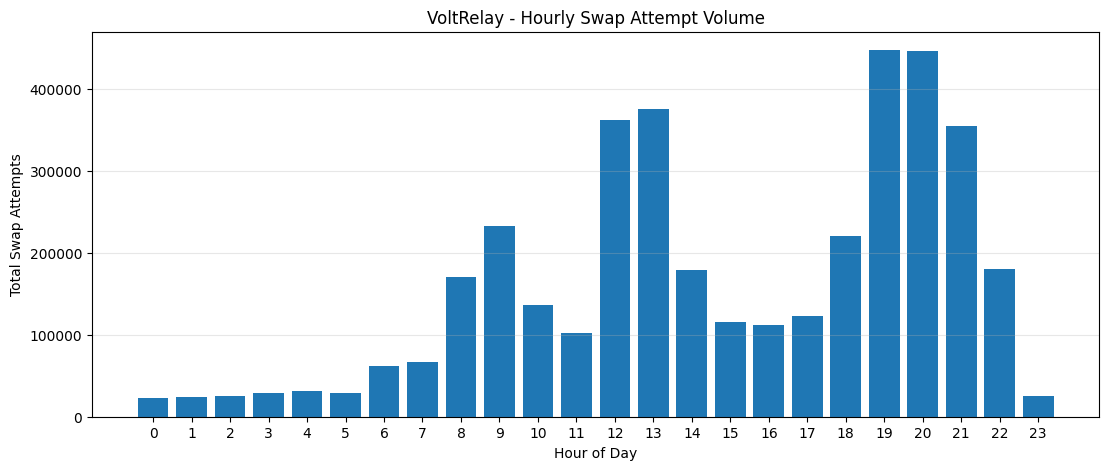

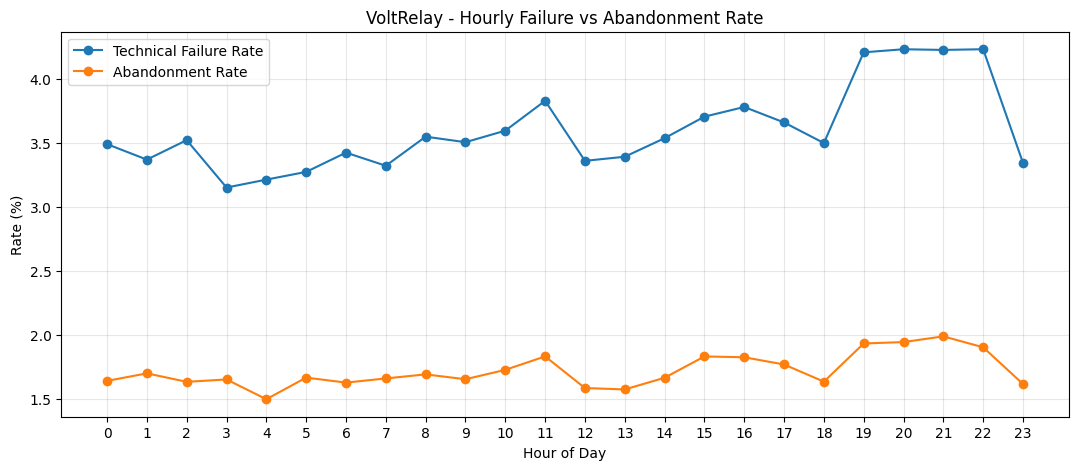

In [35]:
import matplotlib.pyplot as plt

# Chart 1: Transaction volume
plt.figure(figsize=(13, 5))

plt.bar(
    hourly_performance.index,
    hourly_performance["total_attempts"]
)

plt.title("VoltRelay - Hourly Swap Attempt Volume")
plt.xlabel("Hour of Day")
plt.ylabel("Total Swap Attempts")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.show()


# Chart 2: Failure and abandonment rates
plt.figure(figsize=(13, 5))

plt.plot(
    hourly_performance.index,
    hourly_performance["failure_rate_pct"],
    marker="o",
    label="Technical Failure Rate"
)

plt.plot(
    hourly_performance.index,
    hourly_performance["abandonment_rate_pct"],
    marker="o",
    label="Abandonment Rate"
)

plt.title("VoltRelay - Hourly Failure vs Abandonment Rate")
plt.xlabel("Hour of Day")
plt.ylabel("Rate (%)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [36]:
import pandas as pd

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

city_hourly_results = []

for chunk in pd.read_csv(file_path, chunksize=200000):

    chunk["event_ts"] = pd.to_datetime(
        chunk["event_ts"], errors="coerce"
    )

    chunk = chunk.dropna(subset=["event_ts"])

    chunk["hour"] = chunk["event_ts"].dt.hour

    chunk["completed"] = (
        chunk["event_type"] == "swap_completed"
    ).astype(int)

    chunk["abandoned"] = (
        chunk["event_type"] == "abandoned_queue"
    ).astype(int)

    chunk["battery_failures"] = (
        chunk["event_type"] == "failed_no_charged_battery"
    ).astype(int)

    chunk["system_failures"] = (
        chunk["event_type"] == "failed_system_error"
    ).astype(int)

    hourly_city = chunk.groupby(
        ["station_id", "hour"]
    ).agg(
        total_attempts=("event_id", "count"),
        completed=("completed", "sum"),
        abandoned=("abandoned", "sum"),
        battery_failures=("battery_failures", "sum"),
        system_failures=("system_failures", "sum")
    ).reset_index()

    city_hourly_results.append(hourly_city)

city_hourly = (
    pd.concat(city_hourly_results)
    .groupby(["station_id", "hour"])
    .sum()
    .reset_index()
)

city_hourly = city_hourly.merge(
    stations[["station_id", "city"]],
    on="station_id",
    how="left"
)

city_hourly = city_hourly.groupby(
    ["city", "hour"]
).sum(numeric_only=True).reset_index()

city_hourly["failure_rate_pct"] = (
    (city_hourly["battery_failures"] +
     city_hourly["system_failures"]) /
    city_hourly["total_attempts"] * 100
)

display(
    city_hourly.pivot(
        index="city",
        columns="hour",
        values="failure_rate_pct"
    ).round(2)
)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
city,,,,,,,,,,,,,,,,,,,,,
Bengaluru,2.71,2.55,3.03,2.80,2.48,2.69,2.85,2.54,3.00,2.81,...,2.99,3.13,3.29,2.83,2.88,2.73,2.69,2.74,2.77,2.37
Delhi NCR,4.71,4.06,4.40,3.79,3.57,4.09,3.91,4.04,4.21,4.19,...,4.14,4.32,4.39,4.44,3.99,5.67,5.75,5.67,5.70,4.26
Hyderabad,3.78,3.65,3.84,3.18,3.73,3.55,3.50,3.73,3.75,3.97,...,3.81,3.95,4.25,4.04,3.85,5.14,4.92,4.98,5.08,4.08
Jaipur,4.23,4.15,4.38,3.76,4.35,4.17,4.41,3.97,4.27,4.30,...,4.49,4.66,4.61,4.64,4.52,6.03,6.29,6.28,6.40,4.02
Mumbai,2.50,2.94,2.53,2.40,2.69,2.50,2.98,2.81,2.94,2.69,...,3.00,3.01,3.00,2.96,2.72,2.56,2.52,2.59,2.43,3.13
Pune,2.93,2.90,2.84,2.95,2.98,2.97,3.04,2.87,3.13,3.06,...,2.88,3.29,3.19,3.12,3.05,3.09,3.27,3.19,3.22,2.86


In [37]:
evening_city = city_hourly[
    city_hourly["hour"].between(19, 22)
].groupby("city").agg(
    total_attempts=("total_attempts", "sum"),
    completed=("completed", "sum"),
    abandoned=("abandoned", "sum"),
    battery_failures=("battery_failures", "sum"),
    system_failures=("system_failures", "sum")
)

evening_city["total_failures"] = (
    evening_city["battery_failures"] +
    evening_city["system_failures"]
)

evening_city["failure_rate_pct"] = (
    evening_city["total_failures"] /
    evening_city["total_attempts"] * 100
)

display(
    evening_city.sort_values(
        "failure_rate_pct", ascending=False
    ).round(2)
)

,total_attempts,completed,abandoned,battery_failures,system_failures,total_failures,failure_rate_pct
city,,,,,,,
Jaipur,179890,162891,5038,10674,515,11189,6.22
Delhi NCR,285423,260571,7356,15425,837,16262,5.70
Hyderabad,262930,242521,6116,12400,809,13209,5.02
Pune,204216,193834,2985,5870,636,6506,3.19
Bengaluru,303939,290395,3945,7386,895,8281,2.72
Mumbai,193239,185118,2379,4324,582,4906,2.54


In [38]:
batteries = pd.read_csv(
    "/content/VoltRelay_Cleaned/batteries_cleaned.csv"
)

print("Shape:", batteries.shape)
print("\nColumns:")
print(batteries.columns.tolist())

display(batteries.head())

Shape: (6500, 13)

Columns:
['battery_id', 'pack_type', 'supplier', 'manufacturing_lot', 'manufacture_date', 'commission_date', 'rated_capacity_kwh', 'purchase_cost_inr', 'initial_soh_pct', 'bms_firmware', 'retired_date', 'retirement_reason', 'current_soh_pct']


,battery_id,pack_type,supplier,manufacturing_lot,manufacture_date,commission_date,rated_capacity_kwh,purchase_cost_inr,initial_soh_pct,bms_firmware,retired_date,retirement_reason,current_soh_pct
0,BAT-2W-100000,2W_2.1kWh,Cellora,CE-2503,2025-01-30,2025-03-19,2.1,31018,99.9,BMS-4.1,NaN,NaN,79.5
1,BAT-2W-100001,2W_2.1kWh,Cellora,CE-2403,2024-02-27,2024-03-30,2.1,34111,99.2,BMS-4.2,NaN,NaN,79.5
2,BAT-3W-100002,3W_4.8kWh,Cellora,CE-2305,2023-04-15,2023-05-11,4.8,66521,99.5,BMS-4.1,NaN,NaN,87.0
3,BAT-2W-100003,2W_2.1kWh,Kyron,KY-2409,2024-09-28,2024-10-09,2.1,32753,99.5,BMS-4.1,2025-06-15,end_of_life,58.1
4,BAT-2W-100004,2W_2.1kWh,Kyron,KY-2407,2024-11-06,2024-11-21,2.1,31734,99.5,BMS-4.2,2025-06-15,end_of_life,60.6


In [39]:
supplier_summary = batteries.groupby("supplier").agg(
    battery_count=("battery_id", "count"),
    avg_initial_soh=("initial_soh_pct", "mean"),
    avg_current_soh=("current_soh_pct", "mean"),
    retired_batteries=("retired_date", "count"),
    avg_purchase_cost=("purchase_cost_inr", "mean")
)

supplier_summary["retirement_rate_pct"] = (
    supplier_summary["retired_batteries"] /
    supplier_summary["battery_count"] * 100
)

display(supplier_summary.round(2))

,battery_count,avg_initial_soh,avg_current_soh,retired_batteries,avg_purchase_cost,retirement_rate_pct
supplier,,,,,,
Amptek,1307,99.19,81.01,0,37724.12,0.00
Cellora,3555,99.18,80.93,0,37245.41,0.00
Kyron,1638,99.21,63.75,1438,37532.74,87.79


In [40]:
batteries["commission_date"] = pd.to_datetime(
    batteries["commission_date"],
    errors="coerce"
)

batteries["retired_date"] = pd.to_datetime(
    batteries["retired_date"],
    errors="coerce"
)

supplier_age = batteries.groupby("supplier").agg(
    battery_count=("battery_id", "count"),
    avg_commission_date=("commission_date", "mean"),
    earliest_commission=("commission_date", "min"),
    latest_commission=("commission_date", "max"),
    retired_batteries=("retired_date", "count")
)

display(supplier_age)

,battery_count,avg_commission_date,earliest_commission,latest_commission,retired_batteries
supplier,,,,,
Amptek,1307,2024-10-20 17:59:43.473603584,2024-03-01,2025-06-14,0
Cellora,3555,2024-04-14 19:53:43.291139072,2023-03-01,2025-05-31,0
Kyron,1638,2024-10-30 02:47:54.725274880,2024-07-01,2025-06-15,1438


In [41]:
# Calculate service life for retired batteries
retired = batteries[
    batteries["retired_date"].notna()
].copy()

retired["service_life_days"] = (
    retired["retired_date"] -
    retired["commission_date"]
).dt.days

# Supplier-wise retirement analysis
retirement_analysis = retired.groupby("supplier").agg(
    retired_count=("battery_id", "count"),
    avg_service_life_days=("service_life_days", "mean"),
    median_service_life_days=("service_life_days", "median"),
    avg_soh_at_recording=("current_soh_pct", "mean")
)

print("Retirement analysis:")
display(retirement_analysis.round(2))

print("\nRetirement reasons:")
display(
    retired.groupby(
        ["supplier", "retirement_reason"]
    ).size().reset_index(name="count")
)

Retirement analysis:


,retired_count,avg_service_life_days,median_service_life_days,avg_soh_at_recording
supplier,,,,
Kyron,1438,239.52,238.0,60.82



Retirement reasons:


,supplier,retirement_reason,count
0,Kyron,end_of_life,1438


In [42]:
pack_summary = batteries.groupby("pack_type").agg(
    battery_count=("battery_id", "count"),
    avg_initial_soh=("initial_soh_pct", "mean"),
    avg_current_soh=("current_soh_pct", "mean"),
    retired_batteries=("retired_date", "count"),
    avg_purchase_cost=("purchase_cost_inr", "mean")
)

pack_summary["retirement_rate_pct"] = (
    pack_summary["retired_batteries"] /
    pack_summary["battery_count"] * 100
)

display(pack_summary.round(2))

,battery_count,avg_initial_soh,avg_current_soh,retired_batteries,avg_purchase_cost,retirement_rate_pct
pack_type,,,,,,
2W_2.1kWh,5518,99.19,75.09,1385,31985.28,25.1
3W_4.8kWh,982,99.21,85.19,53,67919.24,5.4


In [43]:
supplier_pack = batteries.groupby(
    ["supplier", "pack_type"]
).agg(
    battery_count=("battery_id", "count"),
    avg_current_soh=("current_soh_pct", "mean"),
    retired_batteries=("retired_date", "count")
).reset_index()

supplier_pack["retirement_rate_pct"] = (
    supplier_pack["retired_batteries"] /
    supplier_pack["battery_count"] * 100
)

display(supplier_pack.round(2))

,supplier,pack_type,battery_count,avg_current_soh,retired_batteries,retirement_rate_pct
0,Amptek,2W_2.1kWh,1098,79.96,0,0.00
1,Amptek,3W_4.8kWh,209,86.51,0,0.00
2,Cellora,2W_2.1kWh,3035,79.97,0,0.00
3,Cellora,3W_4.8kWh,520,86.52,0,0.00
4,Kyron,2W_2.1kWh,1385,60.53,1385,100.00
5,Kyron,3W_4.8kWh,253,81.35,53,20.95


In [44]:
lot_summary = batteries.groupby(
    ["supplier", "manufacturing_lot", "pack_type"]
).agg(
    battery_count=("battery_id", "count"),
    avg_current_soh=("current_soh_pct", "mean"),
    retired_batteries=("retired_date", "count")
).reset_index()

lot_summary["retirement_rate_pct"] = (
    lot_summary["retired_batteries"] /
    lot_summary["battery_count"] * 100
)

# Show lots containing at least 10 batteries
lot_summary = lot_summary[
    lot_summary["battery_count"] >= 10
]

display(
    lot_summary.sort_values(
        ["retirement_rate_pct", "avg_current_soh"],
        ascending=[False, True]
    ).round(2)
)

,supplier,manufacturing_lot,pack_type,battery_count,avg_current_soh,retired_batteries,retirement_rate_pct
86,Kyron,KY-2407,2W_2.1kWh,452,60.51,452,100.00
88,Kyron,KY-2408,2W_2.1kWh,471,60.53,471,100.00
90,Kyron,KY-2409,2W_2.1kWh,462,60.56,462,100.00
87,Kyron,KY-2407,3W_4.8kWh,28,68.73,24,85.71
89,Kyron,KY-2408,3W_4.8kWh,29,69.47,18,62.07
...,...,...,...,...,...,...,...
98,Kyron,KY-2416,3W_4.8kWh,20,86.76,0,0.00
45,Cellora,CE-2309,3W_4.8kWh,19,86.77,0,0.00
7,Amptek,AM-2406,3W_4.8kWh,12,86.83,0,0.00
43,Cellora,CE-2308,3W_4.8kWh,19,86.85,0,0.00


In [45]:
kyron_lots = lot_summary[
    lot_summary["supplier"] == "Kyron"
].sort_values(
    ["pack_type", "manufacturing_lot"]
)

display(kyron_lots.round(2))

,supplier,manufacturing_lot,pack_type,battery_count,avg_current_soh,retired_batteries,retirement_rate_pct
86,Kyron,KY-2407,2W_2.1kWh,452,60.51,452,100.00
88,Kyron,KY-2408,2W_2.1kWh,471,60.53,471,100.00
90,Kyron,KY-2409,2W_2.1kWh,462,60.56,462,100.00
87,Kyron,KY-2407,3W_4.8kWh,28,68.73,24,85.71
89,Kyron,KY-2408,3W_4.8kWh,29,69.47,18,62.07
91,Kyron,KY-2409,3W_4.8kWh,19,69.54,11,57.89
92,Kyron,KY-2410,3W_4.8kWh,17,86.26,0,0.00
93,Kyron,KY-2411,3W_4.8kWh,21,86.59,0,0.00
94,Kyron,KY-2412,3W_4.8kWh,21,86.47,0,0.00
95,Kyron,KY-2413,3W_4.8kWh,24,86.66,0,0.00


In [46]:
display(monthly.head())
display(monthly.columns)

,month,event_type,total_events,revenue_inr,avg_queue_wait_sec
0,2024-01,abandoned_queue,1405,0.0,702.567972
1,2024-01,cancelled_by_rider,445,0.0,44.979775
2,2024-01,failed_no_charged_battery,2690,0.0,29.100000
3,2024-01,failed_system_error,318,0.0,42.496855
4,2024-01,swap_completed,105490,6318995.2,243.027178


Index(['month', 'event_type', 'total_events', 'revenue_inr',
       'avg_queue_wait_sec'],
      dtype='object')

In [47]:
monthly_revenue = monthly.pivot_table(
    index="month",
    columns="event_type",
    values="revenue_inr",
    aggfunc="sum",
    fill_value=0
).reset_index()

monthly_completed = monthly.pivot_table(
    index="month",
    columns="event_type",
    values="total_events",
    aggfunc="sum",
    fill_value=0
).reset_index()

monthly_revenue = monthly_revenue[["month", "swap_completed"]]

monthly_completed = monthly_completed[["month", "swap_completed"]]

monthly_revenue = monthly_revenue.rename(
    columns={"swap_completed": "revenue_inr"}
)

monthly_completed = monthly_completed.rename(
    columns={"swap_completed": "completed_swaps"}
)

monthly_financial = monthly_revenue.merge(
    monthly_completed,
    on="month"
)

display(monthly_financial.round(2))

event_type,month,revenue_inr,completed_swaps
0,2024-01,6318995.20,105490
1,2024-02,6387614.80,106582
2,2024-03,7093617.00,118444
3,2024-04,7370255.80,122836
4,2024-05,7689594.00,128328
5,2024-06,8003275.60,133743
6,2024-07,9879524.60,151824
7,2024-08,10724296.65,164931
8,2024-09,12115209.50,187302
9,2024-10,14577271.65,219838


In [48]:
monthly_financial["revenue_per_swap"] = (
    monthly_financial["revenue_inr"] /
    monthly_financial["completed_swaps"]
)

monthly_financial["revenue_growth_pct"] = (
    monthly_financial["revenue_inr"].pct_change() * 100
)

monthly_financial["swap_growth_pct"] = (
    monthly_financial["completed_swaps"].pct_change() * 100
)

display(monthly_financial.round(2))

event_type,month,revenue_inr,completed_swaps,revenue_per_swap,revenue_growth_pct,swap_growth_pct
0,2024-01,6318995.20,105490,59.90,NaN,NaN
1,2024-02,6387614.80,106582,59.93,1.09,1.04
2,2024-03,7093617.00,118444,59.89,11.05,11.13
3,2024-04,7370255.80,122836,60.00,3.90,3.71
4,2024-05,7689594.00,128328,59.92,4.33,4.47
5,2024-06,8003275.60,133743,59.84,4.08,4.22
6,2024-07,9879524.60,151824,65.07,23.44,13.52
7,2024-08,10724296.65,164931,65.02,8.55,8.63
8,2024-09,12115209.50,187302,64.68,12.97,13.56
9,2024-10,14577271.65,219838,66.31,20.32,17.37


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand operational trends, identify patterns and discover potential business problems in VoltRelay's EV battery-swapping network.

The analysis covers:

### 3.1 Network Performance
- Monthly swap attempts and completed swaps.
- Completion, technical failure and abandonment rates.
- Revenue trends over time.

### 3.2 Geographic Performance
- City-wise technical failure rates.
- Station-level performance.
- Identification of high-failure stations.

### 3.3 Hourly Performance
- Swap demand by hour.
- Hourly technical failure rates.
- Customer abandonment patterns.

Visualizations are used to identify operational trends and areas requiring further investigation.

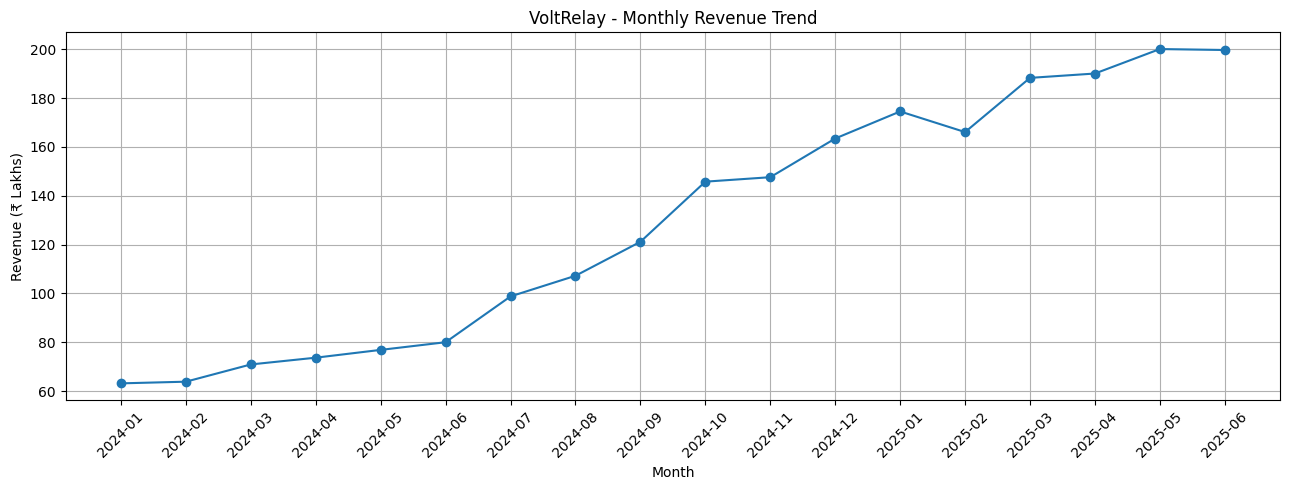

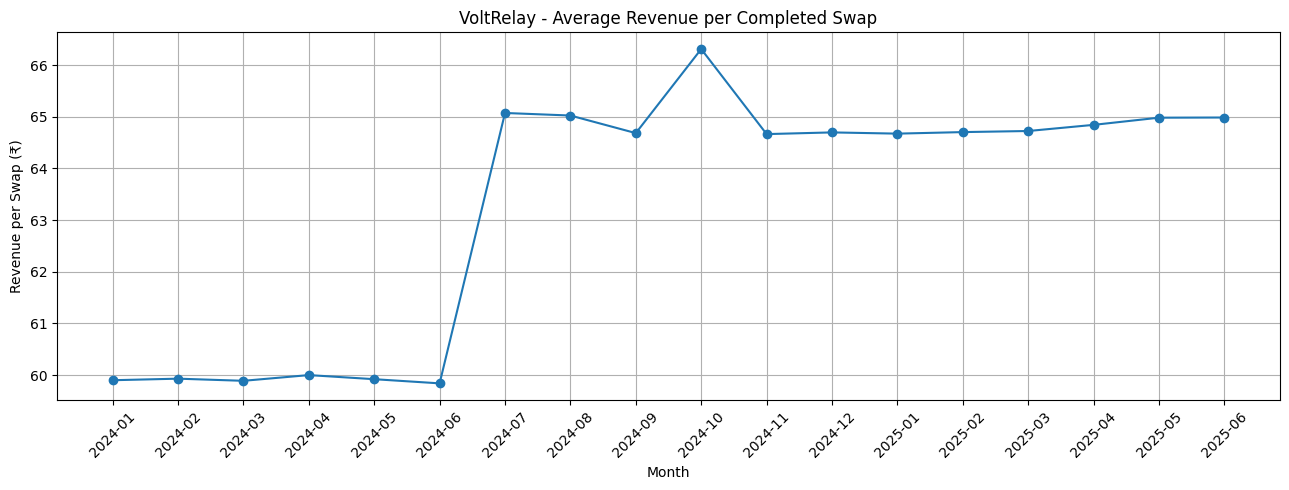

In [49]:
import matplotlib.pyplot as plt

# Chart 1: Monthly revenue
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_financial["month"],
    monthly_financial["revenue_inr"] / 100000,
    marker="o"
)

plt.title("VoltRelay - Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹ Lakhs)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# Chart 2: Average revenue per completed swap
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_financial["month"],
    monthly_financial["revenue_per_swap"],
    marker="o"
)

plt.title("VoltRelay - Average Revenue per Completed Swap")
plt.xlabel("Month")
plt.ylabel("Revenue per Swap (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [50]:
import pandas as pd

pricing_parts = []

for chunk in pd.read_csv(
    "/content/VoltRelay_Cleaned/swap_events_cleaned.csv",
    usecols=[
        "event_ts",
        "event_type",
        "tariff_code",
        "list_price_inr",
        "discount_inr",
        "amount_charged_inr"
    ],
    chunksize=200000
):

    completed = chunk[
        chunk["event_type"] == "swap_completed"
    ].copy()

    completed["month"] = pd.to_datetime(
        completed["event_ts"]
    ).dt.to_period("M").astype(str)

    summary = completed.groupby(
        ["month", "tariff_code"]
    ).agg(
        completed_swaps=("event_type", "count"),
        total_list_price=("list_price_inr", "sum"),
        total_discount=("discount_inr", "sum"),
        total_revenue=("amount_charged_inr", "sum")
    ).reset_index()

    pricing_parts.append(summary)

pricing_monthly = pd.concat(
    pricing_parts,
    ignore_index=True
)

pricing_monthly = pricing_monthly.groupby(
    ["month", "tariff_code"],
    as_index=False
).sum()

pricing_monthly["avg_list_price"] = (
    pricing_monthly["total_list_price"] /
    pricing_monthly["completed_swaps"]
)

pricing_monthly["avg_discount"] = (
    pricing_monthly["total_discount"] /
    pricing_monthly["completed_swaps"]
)

pricing_monthly["avg_amount_charged"] = (
    pricing_monthly["total_revenue"] /
    pricing_monthly["completed_swaps"]
)

display(
    pricing_monthly[
        pricing_monthly["month"].isin(
            ["2024-06", "2024-07", "2024-08",
             "2024-09", "2024-10", "2024-11"]
        )
    ].round(2)
)

,month,tariff_code,completed_swaps,total_list_price,total_discount,total_revenue,avg_list_price,avg_discount,avg_amount_charged
10,2024-06,PARTNER,88048,5761960.0,599949.40,5161970.60,65.44,6.81,58.63
11,2024-06,STD,45695,2841420.0,0.00,2841305.00,62.18,0.00,62.18
12,2024-07,PARTNER,99486,7084980.0,738545.40,6346634.60,71.22,7.42,63.79
13,2024-07,STD,52338,3533010.0,0.00,3532890.00,67.50,0.00,67.50
14,2024-08,PARTNER,108361,7709825.0,805583.35,6904331.65,71.15,7.43,63.72
15,2024-08,STD,56570,3819925.0,0.00,3819965.00,67.53,0.00,67.53
16,2024-09,PARTNER,123240,8717595.0,914095.50,7803384.50,70.74,7.42,63.32
17,2024-09,STD,64062,4311810.0,0.00,4311825.00,67.31,0.00,67.31
18,2024-10,OFFPEAK,3229,217355.0,0.00,191553.00,67.31,0.00,59.32
19,2024-10,PARTNER,145755,10283535.0,1079868.35,9387548.65,70.55,7.41,64.41


In [51]:
pricing_monthly["tariff_share_pct"] = (
    pricing_monthly["completed_swaps"] /
    pricing_monthly.groupby("month")["completed_swaps"].transform("sum")
) * 100

display(
    pricing_monthly[
        pricing_monthly["month"].isin([
            "2024-06", "2024-07", "2024-08",
            "2024-09", "2024-10", "2024-11",
            "2024-12", "2025-01", "2025-02",
            "2025-03", "2025-04", "2025-05", "2025-06"
        ])
    ][[
        "month",
        "tariff_code",
        "completed_swaps",
        "tariff_share_pct",
        "avg_list_price",
        "avg_discount",
        "avg_amount_charged"
    ]].round(2)
)

,month,tariff_code,completed_swaps,tariff_share_pct,avg_list_price,avg_discount,avg_amount_charged
10,2024-06,PARTNER,88048,65.83,65.44,6.81,58.63
11,2024-06,STD,45695,34.17,62.18,0.00,62.18
12,2024-07,PARTNER,99486,65.53,71.22,7.42,63.79
13,2024-07,STD,52338,34.47,67.50,0.00,67.50
14,2024-08,PARTNER,108361,65.70,71.15,7.43,63.72
15,2024-08,STD,56570,34.30,67.53,0.00,67.53
16,2024-09,PARTNER,123240,65.80,70.74,7.42,63.32
17,2024-09,STD,64062,34.20,67.31,0.00,67.31
18,2024-10,OFFPEAK,3229,1.47,67.31,0.00,59.32
19,2024-10,PARTNER,145755,66.30,70.55,7.41,64.41


In [52]:
import pandas as pd

stations_cost = stations[
    ["station_id", "grid_tariff_inr_kwh"]
].copy()

cost_parts = []

for chunk in pd.read_csv(
    "/content/VoltRelay_Cleaned/swap_events_cleaned.csv",
    usecols=[
        "station_id",
        "event_ts",
        "event_type",
        "energy_to_recharge_kwh"
    ],
    chunksize=200000
):

    completed = chunk[
        chunk["event_type"] == "swap_completed"
    ].copy()

    completed["month"] = pd.to_datetime(
        completed["event_ts"]
    ).dt.to_period("M").astype(str)

    completed = completed.merge(
        stations_cost,
        on="station_id",
        how="left"
    )

    completed["estimated_energy_cost"] = (
        completed["energy_to_recharge_kwh"] *
        completed["grid_tariff_inr_kwh"]
    )

    summary = completed.groupby("month").agg(
        completed_swaps=("event_type", "count"),
        energy_kwh=("energy_to_recharge_kwh", "sum"),
        estimated_energy_cost_inr=(
            "estimated_energy_cost", "sum"
        ),
        missing_energy=("energy_to_recharge_kwh", "count"),
        missing_tariff=("grid_tariff_inr_kwh", "count")
    ).reset_index()

    cost_parts.append(summary)

monthly_energy_cost = pd.concat(
    cost_parts,
    ignore_index=True
).groupby("month", as_index=False).sum()

monthly_energy_cost["energy_cost_per_swap"] = (
    monthly_energy_cost["estimated_energy_cost_inr"] /
    monthly_energy_cost["completed_swaps"]
)

display(monthly_energy_cost.round(2))

,month,completed_swaps,energy_kwh,estimated_energy_cost_inr,missing_energy,missing_tariff,energy_cost_per_swap
0,2024-01,105490,249226.16,2320971.24,105490,105490,22.00
1,2024-02,106582,250600.86,2334290.44,106582,106582,21.90
2,2024-03,118444,276136.55,2572346.56,118444,118444,21.72
3,2024-04,122836,284847.97,2652598.93,122836,122836,21.59
4,2024-05,128328,293857.00,2738029.26,128328,128328,21.34
5,2024-06,133743,302435.53,2813405.94,133743,133743,21.04
6,2024-07,151824,341190.92,3166309.81,151824,151824,20.86
7,2024-08,164931,366727.45,3405336.13,164931,164931,20.65
8,2024-09,187302,412034.06,3830745.92,187302,187302,20.45
9,2024-10,219838,476850.31,4444666.63,219838,219838,20.22


In [54]:
missing_energy=("energy_to_recharge_kwh", "count"),
missing_tariff=("grid_tariff_inr_kwh", "count")

In [55]:
print("monthly_financial exists:", "monthly_financial" in globals())
print("monthly_energy_cost exists:", "monthly_energy_cost" in globals())

monthly_financial exists: True
monthly_energy_cost exists: True


In [56]:
print("MONTHLY FINANCIAL:")
print(monthly_financial.columns.tolist())

print("\nMONTHLY ENERGY COST:")
print(monthly_energy_cost.columns.tolist())

MONTHLY FINANCIAL:
['month', 'revenue_inr', 'completed_swaps', 'revenue_per_swap', 'revenue_growth_pct', 'swap_growth_pct']

MONTHLY ENERGY COST:
['month', 'completed_swaps', 'energy_kwh', 'estimated_energy_cost_inr', 'missing_energy', 'missing_tariff', 'energy_cost_per_swap']


In [57]:
profitability = monthly_financial.merge(
    monthly_energy_cost,
    on="month",
    suffixes=("_revenue", "_cost")
)

# Calculate contribution after estimated electricity cost
profitability["contribution_after_electricity"] = (
    profitability["revenue_inr"] -
    profitability["estimated_energy_cost_inr"]
)

# Calculate contribution per completed swap
profitability["contribution_per_swap"] = (
    profitability["contribution_after_electricity"] /
    profitability["completed_swaps_revenue"]
)

# Calculate contribution margin percentage
profitability["contribution_margin_pct"] = (
    profitability["contribution_after_electricity"] /
    profitability["revenue_inr"] * 100
)

display(profitability[[
    "month",
    "revenue_inr",
    "estimated_energy_cost_inr",
    "contribution_after_electricity",
    "contribution_per_swap",
    "contribution_margin_pct"
]].round(2))

,month,revenue_inr,estimated_energy_cost_inr,contribution_after_electricity,contribution_per_swap,contribution_margin_pct
0,2024-01,6318995.20,2320971.24,3998023.96,37.90,63.27
1,2024-02,6387614.80,2334290.44,4053324.36,38.03,63.46
2,2024-03,7093617.00,2572346.56,4521270.44,38.17,63.74
3,2024-04,7370255.80,2652598.93,4717656.87,38.41,64.01
4,2024-05,7689594.00,2738029.26,4951564.74,38.59,64.39
5,2024-06,8003275.60,2813405.94,5189869.66,38.80,64.85
6,2024-07,9879524.60,3166309.81,6713214.79,44.22,67.95
7,2024-08,10724296.65,3405336.13,7318960.52,44.38,68.25
8,2024-09,12115209.50,3830745.92,8284463.58,44.23,68.38
9,2024-10,14577271.65,4444666.63,10132605.02,46.09,69.51


In [58]:
print([
    name for name in globals()
    if "energy" in name.lower() or "cost" in name.lower()
])

['stations_cost', 'cost_parts', 'monthly_energy_cost', 'missing_energy']


In [59]:
print(type(cost_parts))

if isinstance(cost_parts, list):
    print("Number of parts:", len(cost_parts))
    print(cost_parts[0].head())
else:
    print(cost_parts.head())

<class 'list'>
Number of parts: 20
     month  completed_swaps  energy_kwh  estimated_energy_cost_inr  \
0  2024-01           105490  249226.165               2.320971e+06   
1  2024-02            85642  201510.358               1.876751e+06   

   missing_energy  missing_tariff  
0          105490          105490  
1           85642           85642  


In [61]:
station_vars = list(globals().keys())

for name in station_vars:
    if "station" in name.lower():
        obj = globals().get(name)
        if hasattr(obj, "shape"):
            print(name, obj.shape)

stations (152, 22)
city_station_count (6,)
station_city (152, 2)
station_counts (151, 5)
station_performance (152, 12)
worst_stations (152, 12)
station_details (152, 11)
station_comparison (152, 23)
stations_cost (152, 2)


In [62]:
print("STATION DETAILS:")
print(station_details.columns.tolist())

print("\nSTATIONS COST:")
print(stations_cost.columns.tolist())

print("\nSAMPLE COST DATA:")
display(stations_cost.head())

STATION DETAILS:
['station_id', 'city', 'zone', 'location_type', 'host_type', 'charger_generation', 'connectivity_tier', 'firmware_version', 'slots_2w', 'slots_3w', 'monthly_maintenance_inr']

STATIONS COST:
['station_id', 'grid_tariff_inr_kwh']

SAMPLE COST DATA:


,station_id,grid_tariff_inr_kwh
0,STN-BLR-001,9.29
1,STN-BLR-002,8.41
2,STN-BLR-003,8.66
3,STN-BLR-004,9.19
4,STN-BLR-005,8.68


In [63]:
print("First cost part columns:")
print(cost_parts[0].columns.tolist())

print("\nNumber of rows in each part:")
print([len(part) for part in cost_parts])

First cost part columns:
['month', 'completed_swaps', 'energy_kwh', 'estimated_energy_cost_inr', 'missing_energy', 'missing_tariff']

Number of rows in each part:
[2, 3, 2, 3, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 1, 2, 1, 1]


In [64]:
import pandas as pd

station_energy_parts = []

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

for chunk in pd.read_csv(
    file_path,
    chunksize=200000,
    usecols=[
        "station_id",
        "event_type",
        "energy_to_recharge_kwh"
    ]
):
    completed = chunk[
        chunk["event_type"] == "swap_completed"
    ]

    summary = completed.groupby("station_id").agg(
        completed_swaps=("event_type", "size"),
        energy_kwh=("energy_to_recharge_kwh", "sum")
    ).reset_index()

    station_energy_parts.append(summary)

print("Processing completed!")
print("Chunks processed:", len(station_energy_parts))

Processing completed!
Chunks processed: 20


In [65]:
station_energy = (
    pd.concat(station_energy_parts)
    .groupby("station_id", as_index=False)
    .agg(
        completed_swaps=("completed_swaps", "sum"),
        energy_kwh=("energy_kwh", "sum")
    )
)

station_energy = station_energy.merge(
    stations_cost,
    on="station_id",
    how="left"
)

station_energy["estimated_energy_cost_inr"] = (
    station_energy["energy_kwh"] *
    station_energy["grid_tariff_inr_kwh"]
)

station_energy["energy_cost_per_swap"] = (
    station_energy["estimated_energy_cost_inr"] /
    station_energy["completed_swaps"]
)

print("Station-level energy analysis:", station_energy.shape)
display(station_energy.head(10).round(2))

Station-level energy analysis: (152, 6)


,station_id,completed_swaps,energy_kwh,grid_tariff_inr_kwh,estimated_energy_cost_inr,energy_cost_per_swap
0,STN-BLR-001,25006,55718.56,9.29,517625.39,20.70
1,STN-BLR-002,29568,60539.70,8.41,509138.85,17.22
2,STN-BLR-003,38521,79236.27,8.66,686186.13,17.81
3,STN-BLR-004,49670,108250.54,9.19,994822.50,20.03
4,STN-BLR-005,25101,56399.98,8.68,489551.85,19.50
5,STN-BLR-006,29749,63592.30,8.66,550709.36,18.51
6,STN-BLR-007,23006,47603.03,9.92,472222.03,20.53
7,STN-BLR-008,29860,62825.07,8.74,549091.10,18.39
8,STN-BLR-009,37327,80106.24,9.34,748192.29,20.04
9,STN-BLR-010,28583,58610.23,9.22,540386.32,18.91


In [66]:
station_city_cost = station_energy.merge(
    station_details[["station_id", "city"]],
    on="station_id",
    how="left"
)

city_energy_cost = (
    station_city_cost.groupby("city")
    .agg(
        station_count=("station_id", "nunique"),
        completed_swaps=("completed_swaps", "sum"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_energy_cost_inr=("estimated_energy_cost_inr", "sum")
    )
    .reset_index()
)

city_energy_cost["energy_cost_per_swap"] = (
    city_energy_cost["total_energy_cost_inr"] /
    city_energy_cost["completed_swaps"]
)

city_energy_cost["energy_kwh_per_swap"] = (
    city_energy_cost["total_energy_kwh"] /
    city_energy_cost["completed_swaps"]
)

city_energy_cost = city_energy_cost.sort_values(
    "energy_cost_per_swap",
    ascending=False
)

display(city_energy_cost.round(2))


,city,station_count,completed_swaps,total_energy_kwh,total_energy_cost_inr,energy_cost_per_swap,energy_kwh_per_swap
4,Mumbai,22,506718,1076612.54,11067198.82,21.84,2.12
0,Bengaluru,34,787697,1654397.45,15281348.64,19.40,2.10
3,Jaipur,18,449366,942177.09,8704690.94,19.37,2.10
2,Hyderabad,26,664312,1380886.29,12661837.28,19.06,2.08
1,Delhi NCR,30,712385,1475992.26,13459592.19,18.89,2.07
5,Pune,22,525331,1100331.21,9912458.24,18.87,2.09


In [67]:
city_energy_cost["effective_tariff_per_kwh"] = (
    city_energy_cost["total_energy_cost_inr"] /
    city_energy_cost["total_energy_kwh"]
)

display(
    city_energy_cost[[
        "city",
        "energy_kwh_per_swap",
        "effective_tariff_per_kwh",
        "energy_cost_per_swap"
    ]].round(2)
)

,city,energy_kwh_per_swap,effective_tariff_per_kwh,energy_cost_per_swap
4,Mumbai,2.12,10.28,21.84
0,Bengaluru,2.10,9.24,19.40
3,Jaipur,2.10,9.24,19.37
2,Hyderabad,2.08,9.17,19.06
1,Delhi NCR,2.07,9.12,18.89
5,Pune,2.09,9.01,18.87


In [69]:
station_city_cost["energy_kwh_per_swap"] = (
    station_city_cost["energy_kwh"] /
    station_city_cost["completed_swaps"]
)

top_energy_cost_stations = station_city_cost.sort_values(
    "energy_cost_per_swap",
    ascending=False
)

display(
    top_energy_cost_stations[[
        "station_id",
        "city",
        "completed_swaps",
        "energy_kwh_per_swap",
        "grid_tariff_inr_kwh",
        "energy_cost_per_swap"
    ]].head(10).round(2)
)

,station_id,city,completed_swaps,energy_kwh_per_swap,grid_tariff_inr_kwh,energy_cost_per_swap
117,STN-MUM-122,Mumbai,27956,2.29,11.10,25.37
107,STN-MUM-112,Mumbai,33744,2.13,11.70,24.95
109,STN-MUM-114,Mumbai,26903,2.12,11.25,23.85
106,STN-MUM-111,Mumbai,29496,2.16,10.91,23.51
111,STN-MUM-116,Mumbai,34672,2.10,11.15,23.38
91,STN-JAI-136,Jaipur,26785,2.30,10.07,23.20
116,STN-MUM-121,Mumbai,34469,2.20,10.44,22.92
16,STN-BLR-017,Bengaluru,22829,2.20,10.15,22.30
62,STN-HYD-063,Hyderabad,34787,2.04,10.85,22.14
90,STN-JAI-135,Jaipur,27493,2.09,10.51,22.00


## 4. Battery Health and Supplier Performance Analysis

This section examines battery health, supplier performance and retirement patterns.

The analysis includes:

- Initial and current State of Health (SOH).
- Battery retirement rates by supplier.
- Battery performance by pack type (2W and 3W).
- Supplier-wise and manufacturing-lot-wise retirement patterns.
- Average battery service life.

The objective is to identify battery performance concerns and highlight suppliers or manufacturing lots requiring further investigation.

**Key observation:** Kyron accounts for all 1,438 retired batteries, with an overall retirement rate of 87.79%.

This association requires further investigation and does not independently establish a manufacturing defect.

In [70]:
top_energy_consumption = station_city_cost.sort_values(
    "energy_kwh_per_swap",
    ascending=False
)

display(
    top_energy_consumption[[
        "station_id",
        "city",
        "completed_swaps",
        "energy_kwh_per_swap",
        "grid_tariff_inr_kwh",
        "energy_cost_per_swap"
    ]].head(10).round(2)
)

,station_id,city,completed_swaps,energy_kwh_per_swap,grid_tariff_inr_kwh,energy_cost_per_swap
91,STN-JAI-136,Jaipur,26785,2.30,10.07,23.20
117,STN-MUM-122,Mumbai,27956,2.29,11.10,25.37
76,STN-HYD-077,Hyderabad,34621,2.25,8.21,18.49
132,STN-PUN-093,Pune,32458,2.25,7.84,17.63
4,STN-BLR-005,Bengaluru,25101,2.25,8.68,19.50
110,STN-MUM-115,Mumbai,33669,2.24,9.47,21.22
0,STN-BLR-001,Bengaluru,25006,2.23,9.29,20.70
67,STN-HYD-068,Hyderabad,34943,2.22,9.21,20.48
97,STN-JAI-142,Jaipur,30405,2.22,9.10,20.21
13,STN-BLR-014,Bengaluru,21775,2.22,9.67,21.44


In [71]:
high_energy_details = top_energy_consumption.head(10).merge(
    station_details[[
        "station_id",
        "charger_generation",
        "connectivity_tier",
        "firmware_version",
        "location_type",
        "host_type"
    ]],
    on="station_id",
    how="left"
)

display(high_energy_details[[
    "station_id",
    "city",
    "energy_kwh_per_swap",
    "grid_tariff_inr_kwh",
    "charger_generation",
    "connectivity_tier",
    "firmware_version",
    "location_type",
    "host_type"
]].round(2))

,station_id,city,energy_kwh_per_swap,grid_tariff_inr_kwh,charger_generation,connectivity_tier,firmware_version,location_type,host_type
0,STN-JAI-136,Jaipur,2.30,10.07,Gen1,good,v3.2.0,transit_hub,mall_parking
1,STN-MUM-122,Mumbai,2.29,11.10,Gen2,good,v3.2.0,market,mall_parking
2,STN-HYD-077,Hyderabad,2.25,8.21,Gen1,good,v3.2.1,market,kirana
3,STN-PUN-093,Pune,2.25,7.84,Gen1,fair,v3.2.1,commercial_hub,fuel_retailer
4,STN-BLR-005,Bengaluru,2.25,8.68,Gen1,fair,v3.2.1,residential,mall_parking
5,STN-MUM-115,Mumbai,2.24,9.47,Gen1,fair,v3.2.1,commercial_hub,kirana
6,STN-BLR-001,Bengaluru,2.23,9.29,Gen1,good,v3.2.1,transit_hub,mall_parking
7,STN-HYD-068,Hyderabad,2.22,9.21,Gen1,good,v3.2.0,commercial_hub,kirana
8,STN-JAI-142,Jaipur,2.22,9.10,Gen1,poor,v3.2.0,commercial_hub,mall_parking
9,STN-BLR-014,Bengaluru,2.22,9.67,Gen1,good,v3.2.1,market,owned_lot


In [72]:
generation_energy = station_city_cost.merge(
    station_details[["station_id", "charger_generation"]],
    on="station_id",
    how="left"
)

generation_comparison = (
    generation_energy.groupby("charger_generation")
    .agg(
        station_count=("station_id", "nunique"),
        completed_swaps=("completed_swaps", "sum"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_energy_cost=("estimated_energy_cost_inr", "sum")
    )
    .reset_index()
)

generation_comparison["energy_kwh_per_swap"] = (
    generation_comparison["total_energy_kwh"] /
    generation_comparison["completed_swaps"]
)

generation_comparison["energy_cost_per_swap"] = (
    generation_comparison["total_energy_cost"] /
    generation_comparison["completed_swaps"]
)

display(generation_comparison.round(2))

,charger_generation,station_count,completed_swaps,total_energy_kwh,total_energy_cost,energy_kwh_per_swap,energy_cost_per_swap
0,Gen1,51,1690298,3653726.18,33515176.12,2.16,19.83
1,Gen2,64,1601293,3325790.52,31542325.56,2.08,19.70
2,Gen3,37,354218,650880.15,6029624.43,1.84,17.02


In [73]:
print("RIDER DATA:")
print(riders.columns.tolist())

print("\nRIDER SAMPLE:")
display(riders.head())

RIDER DATA:
['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone', 'signup_date', 'signup_channel', 'plan_type', 'declared_shift', 'age_band', 'kyc_verified', 'home_city']

RIDER SAMPLE:


,rider_id,partner_id,vehicle_class,vehicle_model,home_zone,signup_date,signup_channel,plan_type,declared_shift,age_band,kyc_verified,home_city
0,RD-1000000,FP-04,3W,Kranti Cargo3,DEL-Noida,2023-03-08,field_agent,partner_billed,night,45+,True,Delhi NCR
1,RD-1000001,FP-05,2W,Volt Cub,MUM-Thane,2023-03-08,partner_onboarding,partner_billed,mixed,35-44,True,Mumbai
2,RD-1000002,FP-06,2W,Torq X1,HYD-West,2023-03-08,partner_onboarding,partner_billed,evening,25-34,False,Hyderabad
3,RD-1000003,FP-01,2W,Zipp E2,MUM-Navi Mumbai,2023-03-08,partner_onboarding,partner_billed,evening,25-34,True,Mumbai
4,RD-1000004,FP-02,2W,Zipp E2,HYD-Hitech City,2023-03-08,partner_onboarding,partner_billed,night,NaN,True,Hyderabad


In [74]:
import pandas as pd

rider_activity_parts = []

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

for chunk in pd.read_csv(
    file_path,
    chunksize=200000,
    usecols=["rider_id", "event_type"]
):
    completed = chunk[
        chunk["event_type"] == "swap_completed"
    ]

    rider_summary = (
        completed.groupby("rider_id")
        .size()
        .reset_index(name="completed_swaps")
    )

    rider_activity_parts.append(rider_summary)

# Combine all chunks
rider_activity = (
    pd.concat(rider_activity_parts)
    .groupby("rider_id", as_index=False)
    ["completed_swaps"].sum()
)

# Identify repeat riders
rider_activity["rider_type"] = (
    rider_activity["completed_swaps"]
    .apply(lambda x: "Repeat Rider" if x > 1 else "One-time Rider")
)

print("Total riders with completed swaps:", len(rider_activity))
print("\nRider activity summary:")

display(
    rider_activity["rider_type"]
    .value_counts()
    .to_frame("rider_count")
)

Total riders with completed swaps: 19948

Rider activity summary:


,rider_count
rider_type,
Repeat Rider,19845
One-time Rider,103


In [75]:
monthly_rider_parts = []

for chunk in pd.read_csv(
    file_path,
    chunksize=200000,
    usecols=["rider_id", "event_ts", "event_type"]
):
    completed = chunk[
        chunk["event_type"] == "swap_completed"
    ].copy()

    completed["month"] = pd.to_datetime(
        completed["event_ts"]
    ).dt.to_period("M").astype(str)

    monthly_summary = (
        completed.groupby("month")["rider_id"]
        .nunique()
        .reset_index(name="active_riders")
    )

    monthly_rider_parts.append(monthly_summary)

monthly_active_riders = (
    pd.concat(monthly_rider_parts)
    .groupby("month", as_index=False)
    ["active_riders"].sum()
)

display(monthly_active_riders)

,month,active_riders
0,2024-01,4183
1,2024-02,8504
2,2024-03,4740
3,2024-04,9575
4,2024-05,10267
5,2024-06,5834
6,2024-07,11497
7,2024-08,12537
8,2024-09,13593
9,2024-10,14777


In [76]:

monthly_rider_pairs = []

for chunk in pd.read_csv(
    file_path,
    chunksize=200000,
    usecols=["rider_id", "event_ts", "event_type"]
):
    completed = chunk[
        chunk["event_type"] == "swap_completed"
    ][["rider_id", "event_ts"]].copy()

    completed["month"] = (
        pd.to_datetime(completed["event_ts"], errors="coerce")
        .dt.to_period("M")
        .astype(str)
    )

    monthly_rider_pairs.append(
        completed[["month", "rider_id"]].dropna().drop_duplicates()
    )

monthly_rider_pairs_df = pd.concat(
    monthly_rider_pairs,
    ignore_index=True
)

monthly_rider_pairs_df = monthly_rider_pairs_df.drop_duplicates(
    subset=["month", "rider_id"]
)

monthly_active_riders = (
    monthly_rider_pairs_df.groupby("month")["rider_id"]
    .nunique()
    .reset_index(name="active_riders")
)

display(monthly_active_riders)


,month,active_riders
0,2024-01,4183
1,2024-02,4449
2,2024-03,4740
3,2024-04,5080
4,2024-05,5486
5,2024-06,5834
6,2024-07,6177
7,2024-08,6714
8,2024-09,7236
9,2024-10,7941


## 5. Revenue, Pricing and Electricity Cost Analysis

This section evaluates the financial performance of VoltRelay's battery-swapping operations.

The analysis includes:

- Monthly revenue and completed swap trends.
- Average revenue per completed swap.
- Pricing and tariff-code comparisons.
- Partner discounts and pricing changes.
- Estimated electricity consumption and cost.
- Electricity cost per completed swap.
- Contribution after estimated electricity expenses.

**Key observations:**

- Monthly revenue increased from approximately ₹63.19 lakh in January 2024 to ₹1.997 crore in June 2025.
- Estimated electricity cost per swap declined from ₹22.00 to ₹17.03.
- Estimated contribution margin after electricity improved from 63.27% to 73.80%.

**Note:** Contribution after electricity is not net profit because other operating expenses are excluded.

In [78]:
import pandas as pd

support_tickets = pd.read_csv(
    "/content/VoltRelay_Cleaned/support_tickets_cleaned.csv"
)

print("Shape:", support_tickets.shape)
print("\nColumns:")
print(support_tickets.columns.tolist())

print("\nSample records:")
display(support_tickets.head())

Shape: (44000, 12)

Columns:
['ticket_id', 'rider_id', 'station_id', 'battery_id', 'created_ts', 'channel', 'category', 'rider_comment', 'priority', 'resolution_status', 'resolution_hours', 'csat_score']

Sample records:


,ticket_id,rider_id,station_id,battery_id,created_ts,channel,category,rider_comment,priority,resolution_status,resolution_hours,csat_score
0,TK-0000001,RD-1001097,STN-BLR-016,NaN,2024-01-01 17:44:05,call_center,billing_dispute,amount galat kata hai is baar,low,duplicate,NaN,NaN
1,TK-0000002,RD-1001216,STN-BLR-020,BAT-2W-104489,2024-01-01 22:59:14,partner_escalation,long_queue,queue itna lamba tha ki late ho gaya delivery ...,medium,resolved,5.2,NaN
2,TK-0000003,RD-1001631,STN-JAI-140,BAT-2W-102867,2024-01-01 19:20:12,app_chat,long_queue,queue itna lamba tha ki late ho gaya delivery ...,medium,resolved,16.3,NaN
3,TK-0000004,RD-1002086,STN-DEL-039,BAT-2W-102727,2024-01-01 03:14:33,partner_escalation,long_queue,queue itna lamba tha ki late ho gaya delivery ...,high,resolved,4.4,3.0
4,TK-0000005,RD-1002308,STN-BLR-004,BAT-2W-105975,2024-01-02 01:47:49,app_chat,other,scooter weak lag raha hai aajkal,low,resolved,23.3,1.0


In [79]:
ticket_categories = (
    support_tickets["category"]
    .value_counts()
    .reset_index()
)

ticket_categories.columns = ["category", "ticket_count"]

ticket_categories["percentage"] = (
    ticket_categories["ticket_count"] /
    len(support_tickets) * 100
).round(2)

display(ticket_categories)

,category,ticket_count,percentage
0,no_battery_available,11647,26.47
1,other,9484,21.55
2,low_range,6636,15.08
3,app_issue,5787,13.15
4,long_queue,5731,13.02
5,billing_dispute,4715,10.72


In [80]:
resolution_summary = (
    support_tickets["resolution_status"]
    .value_counts()
    .reset_index()
)

resolution_summary.columns = [
    "resolution_status",
    "ticket_count"
]

resolution_summary["percentage"] = (
    resolution_summary["ticket_count"] /
    len(support_tickets) * 100
).round(2)

display(resolution_summary)

,resolution_status,ticket_count,percentage
0,resolved,37888,86.11
1,unresolved,5175,11.76
2,duplicate,937,2.13


In [81]:
resolved_tickets = support_tickets[
    support_tickets["resolution_status"] == "resolved"
]

print("Resolved tickets:", len(resolved_tickets))

print(
    "Average resolution hours:",
    round(resolved_tickets["resolution_hours"].mean(), 2)
)

print(
    "Median resolution hours:",
    round(resolved_tickets["resolution_hours"].median(), 2)
)

Resolved tickets: 37888
Average resolution hours: 15.95
Median resolution hours: 13.2


In [82]:
csat_data = support_tickets[
    support_tickets["csat_score"].notna()
]

print("Total tickets:", len(support_tickets))
print("Tickets with CSAT:", len(csat_data))
print(
    "CSAT coverage:",
    round(len(csat_data) / len(support_tickets) * 100, 2),
    "%"
)

print(
    "Average CSAT:",
    round(csat_data["csat_score"].mean(), 2)
)

print("\nCSAT distribution:")
display(csat_data["csat_score"].value_counts().sort_index())

Total tickets: 44000
Tickets with CSAT: 15129
CSAT coverage: 34.38 %
Average CSAT: 3.56

CSAT distribution:


,count
csat_score,
1.0,1544
2.0,1789
3.0,3054
4.0,4139
5.0,4603


In [83]:
csat_by_category = (
    csat_data.groupby("category")
    .agg(
        responses=("csat_score", "count"),
        average_csat=("csat_score", "mean"),
        low_ratings=("csat_score", lambda x: (x <= 2).sum())
    )
    .reset_index()
)

csat_by_category["average_csat"] = (
    csat_by_category["average_csat"].round(2)
)

csat_by_category["low_rating_pct"] = (
    csat_by_category["low_ratings"] /
    csat_by_category["responses"] * 100
).round(2)

display(
    csat_by_category.sort_values("average_csat")
)

,category,responses,average_csat,low_ratings,low_rating_pct
2,long_queue,1994,3.51,460,23.07
3,low_range,2325,3.53,534,22.97
0,app_issue,1947,3.54,458,23.52
1,billing_dispute,1620,3.57,348,21.48
5,other,3246,3.57,715,22.03
4,no_battery_available,3997,3.60,818,20.47


In [84]:
fleet_partners = pd.read_csv(
    "/content/VoltRelay_Cleaned/fleet_partners_cleaned.csv"
)

print("Shape:", fleet_partners.shape)

print("\nColumns:")
print(fleet_partners.columns.tolist())

print("\nSample records:")
display(fleet_partners.head())

Shape: (12, 12)

Columns:
['partner_id', 'partner_name', 'partner_segment', 'vehicle_class', 'contract_type', 'contract_start_date', 'discount_pct', 'amendment_date', 'discount_pct_after_amendment', 'peak_surcharge_billable', 'payment_terms_days', 'cities_active']

Sample records:


,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
0,FP-01,FeastFly,food_delivery,2W,volume_tiered,2023-04-01,10.0,NaN,NaN,Y,30,BLR|DEL|HYD|PUN|MUM|JAI
1,FP-02,ParcelNest,ecom_logistics,2W,pay_per_swap,2023-07-01,15.0,NaN,NaN,Y,30,BLR|DEL|HYD|MUM
2,FP-03,ZipDrop,quick_commerce,2W,volume_tiered,2023-06-01,12.0,2024-11-01,28.0,N,45,BLR|DEL|HYD|PUN|MUM|JAI
3,FP-04,CargoTuk,cargo_3w,3W,pay_per_swap,2023-09-01,8.0,NaN,NaN,Y,30,DEL|HYD|JAI
4,FP-05,Swiggle Go,food_delivery,2W,volume_tiered,2023-05-01,11.0,NaN,NaN,N,30,BLR|PUN|MUM


In [85]:
print("ALL FLEET PARTNERS:")
display(fleet_partners)

print("\nDATA TYPES:")
print(fleet_partners.dtypes)

print("\nMISSING VALUES:")
display(fleet_partners.isnull().sum())

ALL FLEET PARTNERS:


,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
0,FP-01,FeastFly,food_delivery,2W,volume_tiered,2023-04-01,10.0,NaN,NaN,Y,30,BLR|DEL|HYD|PUN|MUM|JAI
1,FP-02,ParcelNest,ecom_logistics,2W,pay_per_swap,2023-07-01,15.0,NaN,NaN,Y,30,BLR|DEL|HYD|MUM
2,FP-03,ZipDrop,quick_commerce,2W,volume_tiered,2023-06-01,12.0,2024-11-01,28.0,N,45,BLR|DEL|HYD|PUN|MUM|JAI
3,FP-04,CargoTuk,cargo_3w,3W,pay_per_swap,2023-09-01,8.0,NaN,NaN,Y,30,DEL|HYD|JAI
4,FP-05,Swiggle Go,food_delivery,2W,volume_tiered,2023-05-01,11.0,NaN,NaN,N,30,BLR|PUN|MUM
5,FP-06,RideMitra,bike_taxi,2W,pay_per_swap,2023-08-01,6.0,NaN,NaN,Y,15,BLR|DEL
6,FP-07,QuickCart,quick_commerce,2W,pay_per_swap,2024-01-15,9.0,NaN,NaN,Y,30,DEL|HYD
7,FP-08,DabbaXpress,food_delivery,2W,pay_per_swap,2024-02-01,8.0,NaN,NaN,Y,30,PUN|MUM
8,FP-09,HaulKing,cargo_3w,3W,pay_per_swap,2023-11-01,7.0,NaN,NaN,Y,45,JAI|DEL
9,FP-10,MetroMove,ecom_logistics,mixed,volume_tiered,2024-03-01,12.0,NaN,NaN,Y,30,BLR|MUM



DATA TYPES:
partner_id                       object
partner_name                     object
partner_segment                  object
vehicle_class                    object
contract_type                    object
contract_start_date              object
discount_pct                    float64
amendment_date                   object
discount_pct_after_amendment    float64
peak_surcharge_billable          object
payment_terms_days                int64
cities_active                    object
dtype: object

MISSING VALUES:


,0
partner_id,0
partner_name,0
partner_segment,0
vehicle_class,0
contract_type,0
contract_start_date,0
discount_pct,0
amendment_date,11
discount_pct_after_amendment,11
peak_surcharge_billable,0


In [86]:

import pandas as pd
import numpy as np

# Load rider-to-partner mapping
rider_partner = pd.read_csv(
    "/content/VoltRelay_Cleaned/riders_cleaned.csv",
    usecols=["rider_id", "partner_id"]
)

partner_parts = []

file_path = "/content/VoltRelay_Cleaned/swap_events_cleaned.csv"

for chunk in pd.read_csv(
    file_path,
    chunksize=200000,
    usecols=[
        "rider_id",
        "event_type",
        "amount_charged_inr"
    ]
):
    # Connect each rider to their fleet partner
    chunk = chunk.merge(
        rider_partner,
        on="rider_id",
        how="left"
    )

    # Identify completed swaps
    chunk["completed_flag"] = (
        chunk["event_type"] == "swap_completed"
    ).astype(int)

    # Count revenue only for completed swaps
    chunk["completed_revenue"] = np.where(
        chunk["event_type"] == "swap_completed",
        chunk["amount_charged_inr"],
        0
    )

    summary = chunk.groupby(
        "partner_id",
        dropna=False
    ).agg(
        total_attempts=("event_type", "size"),
        completed_swaps=("completed_flag", "sum"),
        revenue_inr=("completed_revenue", "sum")
    ).reset_index()

    partner_parts.append(summary)

partner_performance = (
    pd.concat(partner_parts)
    .groupby("partner_id", dropna=False, as_index=False)
    .agg(
        total_attempts=("total_attempts", "sum"),
        completed_swaps=("completed_swaps", "sum"),
        revenue_inr=("revenue_inr", "sum")
    )
)

partner_performance["completion_rate_pct"] = (
    partner_performance["completed_swaps"] /
    partner_performance["total_attempts"] * 100
).round(2)

partner_performance["revenue_inr"] = (
    partner_performance["revenue_inr"].round(2)
)

# Attach partner names and contract information
partner_performance = partner_performance.merge(
    fleet_partners,
    on="partner_id",
    how="left"
)

display(
    partner_performance.sort_values(
        "revenue_inr",
        ascending=False
    )
)


,partner_id,total_attempts,completed_swaps,revenue_inr,completion_rate_pct,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
12,NaN,1311535,1235968,84372541.00,94.24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,FP-01,559823,526620,32696006.00,94.07,FeastFly,food_delivery,2W,volume_tiered,2023-04-01,10.0,NaN,NaN,Y,30.0,BLR|DEL|HYD|PUN|MUM|JAI
2,FP-03,592069,557172,29015711.20,94.11,ZipDrop,quick_commerce,2W,volume_tiered,2023-06-01,12.0,2024-11-01,28.0,N,45.0,BLR|DEL|HYD|PUN|MUM|JAI
1,FP-02,319275,302506,17113714.75,94.75,ParcelNest,ecom_logistics,2W,pay_per_swap,2023-07-01,15.0,NaN,NaN,Y,30.0,BLR|DEL|HYD|MUM
4,FP-05,256515,241689,14336840.65,94.22,Swiggle Go,food_delivery,2W,volume_tiered,2023-05-01,11.0,NaN,NaN,N,30.0,BLR|PUN|MUM
3,FP-04,149015,134085,13333431.20,89.98,CargoTuk,cargo_3w,3W,pay_per_swap,2023-09-01,8.0,NaN,NaN,Y,30.0,DEL|HYD|JAI
6,FP-07,137831,129967,8062439.00,94.29,QuickCart,quick_commerce,2W,pay_per_swap,2024-01-15,9.0,NaN,NaN,Y,30.0,DEL|HYD
5,FP-06,127724,120695,7569963.90,94.50,RideMitra,bike_taxi,2W,pay_per_swap,2023-08-01,6.0,NaN,NaN,Y,15.0,BLR|DEL
7,FP-08,99116,93376,5953223.20,94.21,DabbaXpress,food_delivery,2W,pay_per_swap,2024-02-01,8.0,NaN,NaN,Y,30.0,PUN|MUM
8,FP-09,60434,54274,5445913.90,89.81,HaulKing,cargo_3w,3W,pay_per_swap,2023-11-01,7.0,NaN,NaN,Y,45.0,JAI|DEL


In [87]:
named_partners = partner_performance[
    partner_performance["partner_id"].notna()
].copy()

total_partner_revenue = named_partners["revenue_inr"].sum()

named_partners["revenue_share_pct"] = (
    named_partners["revenue_inr"] /
    total_partner_revenue * 100
).round(2)

named_partners["revenue_per_swap"] = (
    named_partners["revenue_inr"] /
    named_partners["completed_swaps"]
).round(2)

display(
    named_partners[
        [
            "partner_name",
            "partner_segment",
            "completed_swaps",
            "revenue_inr",
            "revenue_share_pct",
            "revenue_per_swap"
        ]
    ].sort_values("revenue_inr", ascending=False)
)

,partner_name,partner_segment,completed_swaps,revenue_inr,revenue_share_pct,revenue_per_swap
0,FeastFly,food_delivery,526620,32696006.00,21.98,62.09
2,ZipDrop,quick_commerce,557172,29015711.20,19.51,52.08
1,ParcelNest,ecom_logistics,302506,17113714.75,11.50,56.57
4,Swiggle Go,food_delivery,241689,14336840.65,9.64,59.32
3,CargoTuk,cargo_3w,134085,13333431.20,8.96,99.44
6,QuickCart,quick_commerce,129967,8062439.00,5.42,62.03
5,RideMitra,bike_taxi,120695,7569963.90,5.09,62.72
7,DabbaXpress,food_delivery,93376,5953223.20,4.00,63.76
8,HaulKing,cargo_3w,54274,5445913.90,3.66,100.34
11,UrbanErrand,bike_taxi,83854,5322144.75,3.58,63.47


In [88]:

zipdrop_rider_ids = rider_partner[
    rider_partner["partner_id"] == "FP-03"
]["rider_id"]

zipdrop_monthly_parts = []

for chunk in pd.read_csv(
    file_path,
    chunksize=200000,
    usecols=[
        "rider_id",
        "event_ts",
        "event_type",
        "amount_charged_inr"
    ]
):
    data = chunk[
        chunk["rider_id"].isin(zipdrop_rider_ids)
        & (chunk["event_type"] == "swap_completed")
    ].copy()

    if data.empty:
        continue

    data["month"] = (
        pd.to_datetime(data["event_ts"], errors="coerce")
        .dt.to_period("M")
        .astype(str)
    )

    summary = data.groupby("month").agg(
        completed_swaps=("rider_id", "size"),
        revenue_inr=("amount_charged_inr", "sum")
    ).reset_index()

    zipdrop_monthly_parts.append(summary)

zipdrop_monthly = (
    pd.concat(zipdrop_monthly_parts)
    .groupby("month", as_index=False)
    .agg(
        completed_swaps=("completed_swaps", "sum"),
        revenue_inr=("revenue_inr", "sum")
    )
)

zipdrop_monthly["revenue_per_swap"] = (
    zipdrop_monthly["revenue_inr"] /
    zipdrop_monthly["completed_swaps"]
).round(2)

display(zipdrop_monthly)


,month,completed_swaps,revenue_inr,revenue_per_swap
0,2024-01,15919,876527.2,55.06
1,2024-02,16168,889650.0,55.03
2,2024-03,17880,985796.2,55.13
3,2024-04,18231,1009820.0,55.39
4,2024-05,19006,1051972.0,55.35
5,2024-06,19631,1085801.8,55.31
6,2024-07,22086,1325976.4,60.04
7,2024-08,25036,1499681.4,59.90
8,2024-09,28917,1721653.4,59.54
9,2024-10,33754,2007192.6,59.47


In [89]:
print("PARTNER ANALYSIS VALIDATION")

print(
    "Total attempts:",
    partner_performance["total_attempts"].sum()
)

print(
    "Total completed swaps:",
    partner_performance["completed_swaps"].sum()
)

print(
    "Total partner-level revenue:",
    round(partner_performance["revenue_inr"].sum(), 2)
)

print(
    "Overall monthly revenue:",
    round(monthly_financial["revenue_inr"].sum(), 2)
)

print(
    "Revenue difference:",
    round(
        partner_performance["revenue_inr"].sum()
        - monthly_financial["revenue_inr"].sum(),
        2
    )
)

PARTNER ANALYSIS VALIDATION
Total attempts: 3877013
Total completed swaps: 3645809
Total partner-level revenue: 233126055.55
Overall monthly revenue: 233126055.55
Revenue difference: 0.0


In [91]:
import pandas as pd

timestamp_candidates = pd.read_csv(
    "/content/VoltRelay_Cleaned/timestamp_review_candidates.csv"
)

print("Timestamp review candidates:", len(timestamp_candidates))

Timestamp review candidates: 139490


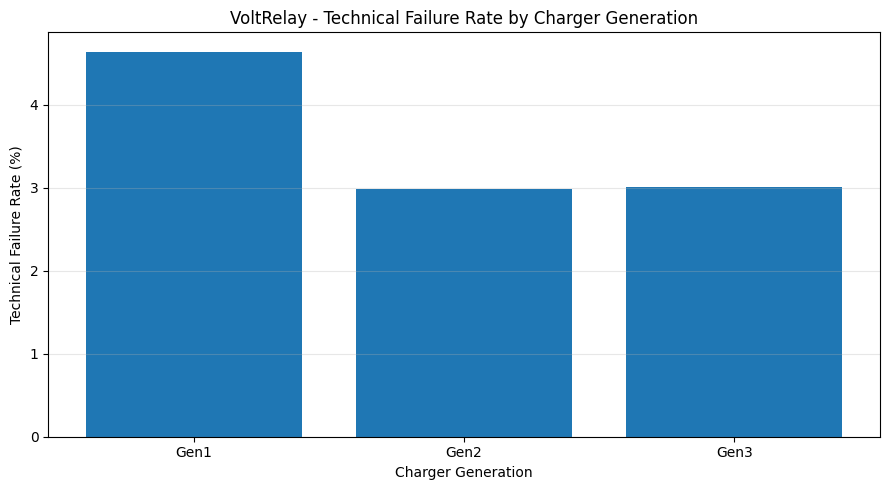

In [92]:
import matplotlib.pyplot as plt
import pandas as pd

generation_data = pd.DataFrame({
    "Charger Generation": ["Gen1", "Gen2", "Gen3"],
    "Failure Rate": [4.64, 2.99, 3.01]
})

plt.figure(figsize=(9, 5))

plt.bar(
    generation_data["Charger Generation"],
    generation_data["Failure Rate"]
)

plt.title("VoltRelay - Technical Failure Rate by Charger Generation")
plt.xlabel("Charger Generation")
plt.ylabel("Technical Failure Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

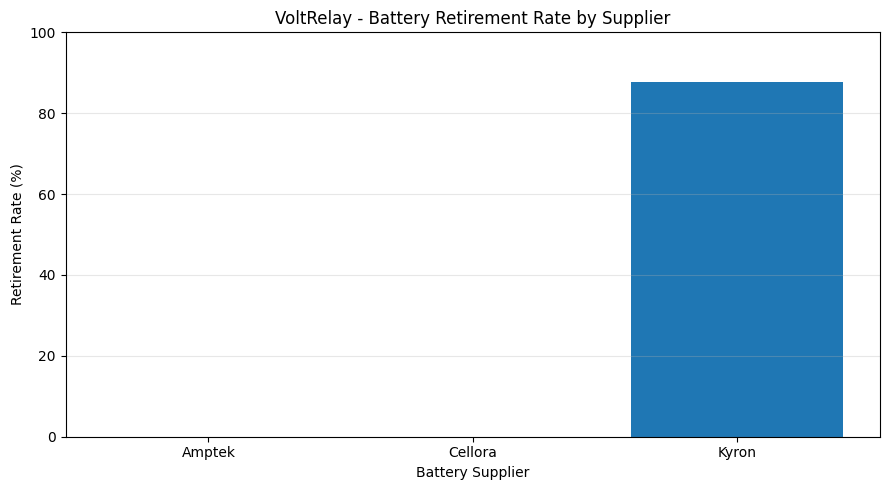

In [93]:
import matplotlib.pyplot as plt
import pandas as pd

supplier_data = pd.DataFrame({
    "Supplier": ["Amptek", "Cellora", "Kyron"],
    "Retirement Rate": [0, 0, 87.79]
})

plt.figure(figsize=(9, 5))

plt.bar(
    supplier_data["Supplier"],
    supplier_data["Retirement Rate"]
)

plt.title("VoltRelay - Battery Retirement Rate by Supplier")
plt.xlabel("Battery Supplier")
plt.ylabel("Retirement Rate (%)")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

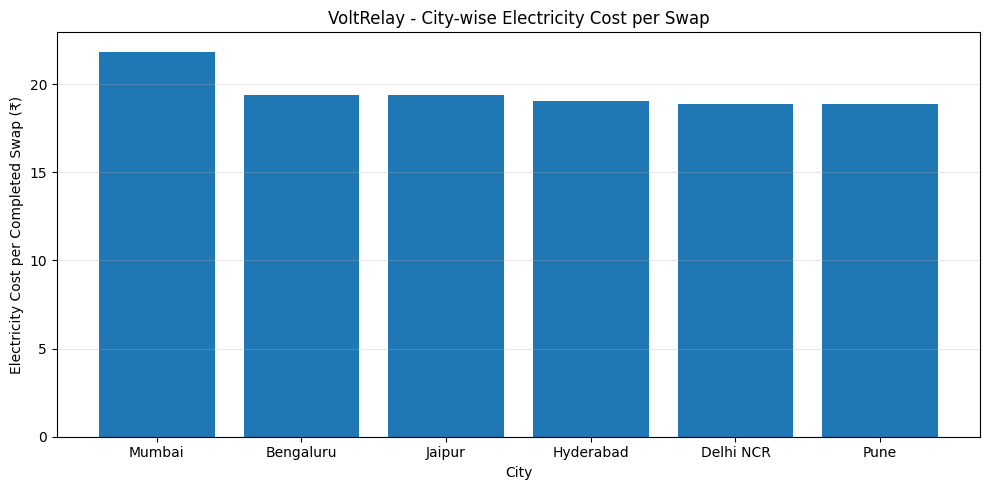

In [94]:
import matplotlib.pyplot as plt
import pandas as pd

city_cost_data = pd.DataFrame({
    "City": [
        "Mumbai", "Bengaluru", "Jaipur",
        "Hyderabad", "Delhi NCR", "Pune"
    ],
    "Cost_per_Swap": [
        21.84, 19.40, 19.37,
        19.06, 18.89, 18.87
    ]
})

plt.figure(figsize=(10, 5))

plt.bar(
    city_cost_data["City"],
    city_cost_data["Cost_per_Swap"]
)

plt.title("VoltRelay - City-wise Electricity Cost per Swap")
plt.xlabel("City")
plt.ylabel("Electricity Cost per Completed Swap (₹)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

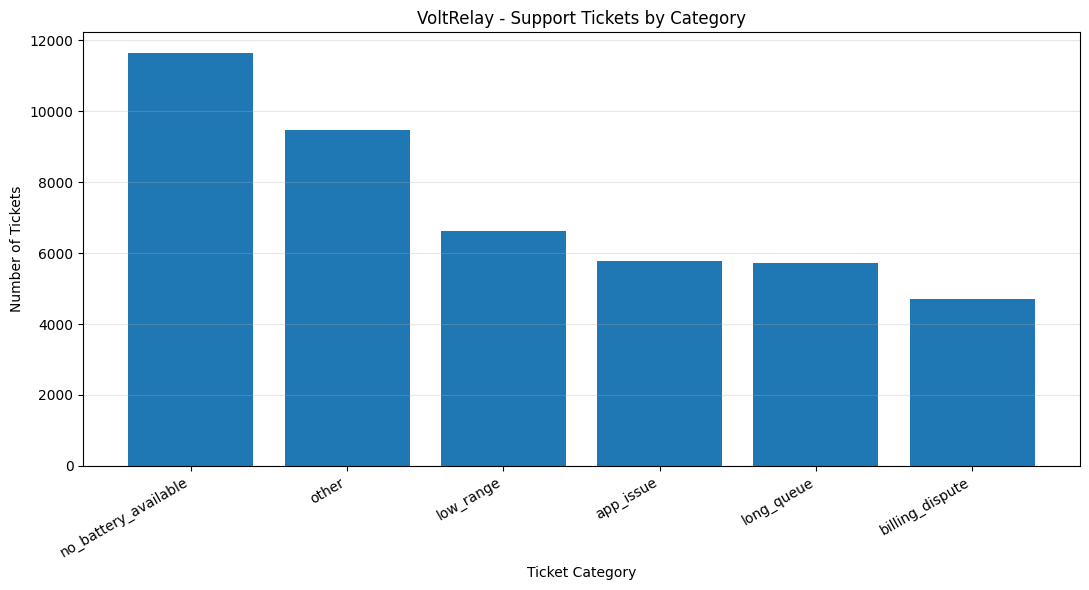

In [95]:
ticket_counts = support_tickets["category"].value_counts()

plt.figure(figsize=(11, 6))

plt.bar(
    ticket_counts.index,
    ticket_counts.values
)

plt.title("VoltRelay - Support Tickets by Category")
plt.xlabel("Ticket Category")
plt.ylabel("Number of Tickets")

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

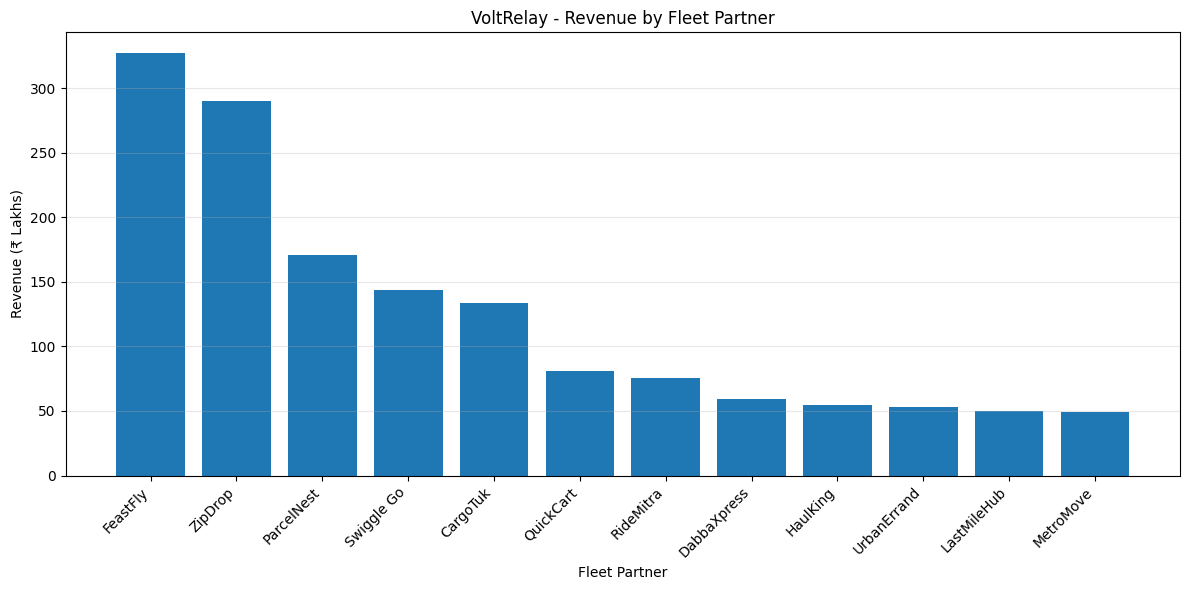

In [96]:
partner_chart = (
    partner_performance[
        partner_performance["partner_name"].notna()
    ]
    .sort_values("revenue_inr", ascending=False)
)

plt.figure(figsize=(12, 6))

plt.bar(
    partner_chart["partner_name"],
    partner_chart["revenue_inr"] / 100000
)

plt.title("VoltRelay - Revenue by Fleet Partner")
plt.xlabel("Fleet Partner")
plt.ylabel("Revenue (₹ Lakhs)")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

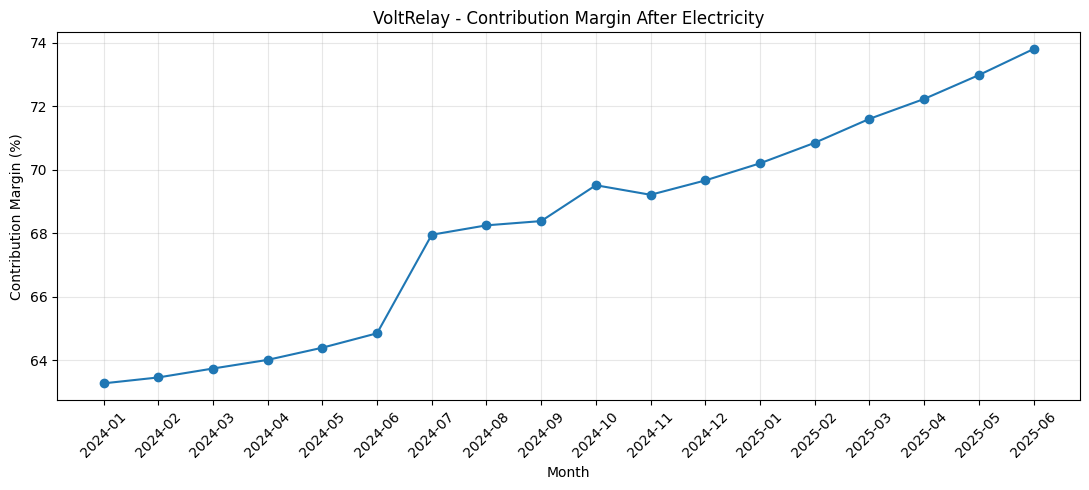

In [97]:
plt.figure(figsize=(11, 5))

plt.plot(
    profitability["month"],
    profitability["contribution_margin_pct"],
    marker="o"
)

plt.title("VoltRelay - Contribution Margin After Electricity")
plt.xlabel("Month")
plt.ylabel("Contribution Margin (%)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Key Business Findings and Recommendations

### 1. Network Reliability
**Finding:** Gen1 chargers recorded a 4.64% technical failure rate, compared with 2.99% for Gen2 and 3.01% for Gen3.

**Recommendation:** Prioritize maintenance and inspection of high-volume Gen1 stations.

### 2. Geographic Performance
**Finding:** Jaipur recorded the highest city-level technical failure rate at 5.06%, followed by Delhi NCR at 4.71%.

**Recommendation:** Investigate high-failure stations in Jaipur and Delhi NCR and improve local operational reliability.

### 3. Peak-Hour Performance
**Finding:** Technical failure rates increased during evening hours, particularly between 7 PM and 10 PM.

**Recommendation:** Review battery availability, station capacity and operational readiness during evening peak periods.

### 4. Battery Performance
**Finding:** All 1,438 recorded retired batteries belonged to supplier Kyron.

**Recommendation:** Investigate Kyron manufacturing lots, battery age and operating conditions before making further procurement decisions.

### 5. Customer Experience
**Finding:** No-battery-available complaints represented 26.47% of support tickets.

**Recommendation:** Improve battery inventory planning and station-level availability monitoring.

### 6. Revenue Performance
**Finding:** Monthly revenue increased from approximately ₹63.19 lakh in January 2024 to ₹1.997 crore in June 2025.

**Recommendation:** Maintain revenue growth while monitoring pricing, discounts and partner economics.

### 7. Electricity Cost
**Finding:** Estimated electricity cost per completed swap declined from ₹22.00 to ₹17.03.

**Recommendation:** Investigate energy-efficient operations and electricity tariff optimization, particularly in Mumbai.

### 8. Fleet Partner Performance
**Finding:** FeastFly and ZipDrop together contributed approximately 41.49% of named fleet-partner revenue.

**Recommendation:** Maintain strategic partner relationships and regularly review partner-specific pricing and discounts.

## Final Conclusion

The analysis of VoltRelay Energy's EV battery-swapping operations from January 2024 to June 2025 reveals opportunities to improve network reliability, battery performance, customer experience and operational efficiency.

The network handled approximately 3.88 million swap attempts, achieving an overall completion rate of 94.04%.

The analysis identified higher technical failure rates among Gen1 chargers, significant battery retirement concentration among Kyron batteries, increased evening failure rates and customer complaints related to battery availability.

At the same time, monthly revenue increased substantially, while estimated electricity cost per completed swap declined.

Based on these findings, VoltRelay should prioritize charger maintenance, battery supplier investigation, improved inventory planning, peak-hour operational readiness and electricity cost optimization.

These recommendations can help strengthen service reliability, improve customer experience and support sustainable business growth.

**Overall, the analysis demonstrates how data-driven decision-making can help VoltRelay identify operational challenges and prioritize business improvements.**